# Settings and utilities

## Plot settings and data paths

In [ ]:
import matplotlib.pyplot as plt
from google.colab import drive
from pathlib import Path

# Set common plot font sizes
plt.rcParams.update(
    {
        "font.size": 16,
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 14,
        "figure.titlesize": 18,
    }
)

# Mount Google Drive and set the dataset root
# Change DATA_ROOT here if the practice folder is renamed or moved
drive.mount("/content/drive")
DATA_ROOT = Path("/content/drive/MyDrive/PHM Practice/Datasets")
PROJECT_ROOT = DATA_ROOT.parent

Mounted at /content/drive


## Shared utility functions

In [ ]:
import numpy as np
import pandas as pd

# Purpose: format displayed numbers without changing their stored values.
# Input: value (number); spec (optional standard Python format).
# Output: formatted text; the input value remains unchanged.
# Used in: CMAPSS processing; MLP in prognosis; CNN in prognosis; LSTM in prognosis; Transformer in
# prognosis; LSTM RUL prediction using 10% of training engines; 1D CNN RUL prediction using 10% of
# training engines; Transformer RUL prediction using 10% of training engines.
def format_number(value, spec=""):
    import numbers

    if not isinstance(value, numbers.Real):
        return format(value, spec)
    value = float(value)
    if spec.endswith(("e", "E", "g", "G", "%")):
        return format(value, spec)
    if 0 < abs(value) < 0.001:
        return f"{value:.3e}"
    precision = 3 if abs(value) < 10 else 2
    import re

    pattern = re.sub(r"\.\d+f$", f".{precision}f", spec) if spec else f".{precision}f"
    return format(value, pattern)

# Purpose: report model layers, parameter counts, and subset sizes.
# Input: model (Keras/PyTorch model), training/validation inputs, optional test.
# Output: printed model structure, parameter counts, and data shapes.
# Used in: MLP in prognosis; CNN in prognosis; LSTM in prognosis; Transformer in prognosis; LSTM RUL
# prediction using 10% of training engines; 1D CNN RUL prediction using 10% of training engines;
# Transformer RUL prediction using 10% of training engines.
def show_model_info(model, training, validation, test=None):
    # Purpose: return the shapes of one or more model inputs.
    # Input: data.
    # Output: returned [tuple(value.shape) for value in values].
    def sample_shape(data):
        values = data if isinstance(data, (list, tuple)) else [data]
        return [tuple(value.shape) for value in values]

    # Purpose: return the number of samples in the model inputs.
    # Input: data.
    # Output: returned len(value).
    def sample_count(data):
        value = data[0] if isinstance(data, (list, tuple)) else data
        return len(value)

    print("Model structure")
    if hasattr(model, "summary"):
        model.summary()
        import numpy as np

        trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
        total = model.count_params()
    else:
        print(model)
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Parameters: {total:,} total; {trainable:,} trainable")
    print(f"Training samples: {sample_count(training):,}")
    print(f"Validation samples: {sample_count(validation):,}")
    print("Training input shapes:", sample_shape(training))
    print("Validation input shapes:", sample_shape(validation))
    if test is not None:
        print(f"Test samples: {sample_count(test):,}")
        print("Test input shapes:", sample_shape(test))

# Purpose: create a callback that reports training and validation losses.
# Input: every (epoch interval, default 100).
# Output: Keras callback for progress reporting.
# Used in: MLP in prognosis; CNN in prognosis; LSTM in prognosis; Transformer in prognosis; LSTM RUL
# prediction using 10% of training engines; 1D CNN RUL prediction using 10% of training engines;
# Transformer RUL prediction using 10% of training engines.
def training_progress(every=100):
    from tensorflow.keras.callbacks import LambdaCallback

    # Purpose: print training and validation loss at the selected epoch interval.
    # Input: epoch, logs.
    # Output: updated state or displayed result; no return value.
    def report(epoch, logs):
        if epoch == 0 or (epoch + 1) % every == 0:
            loss = format_number(logs.get("loss", float("nan")))
            valid = format_number(logs.get("val_loss", float("nan")))
            print(f"Epoch {epoch + 1}: training loss={loss}; validation loss={valid}")

    return LambdaCallback(on_epoch_end=report)

# Purpose: report completed epochs, best losses, and elapsed training time.
# Input: history (Keras history), started (time.perf_counter timestamp).
# Output: printed training summary.
# Used in: MLP in prognosis; CNN in prognosis; LSTM in prognosis; Transformer in prognosis; LSTM RUL
# prediction using 10% of training engines; 1D CNN RUL prediction using 10% of training engines;
# Transformer RUL prediction using 10% of training engines.
def report_training(history, started):
    import time
    import numpy as np

    losses = history.history
    reference = losses.get("val_loss", losses["loss"])
    best = int(np.argmin(reference))
    print(f'Completed epochs: {len(losses["loss"])}; best epoch: {best + 1}')
    print("Best training loss:", format_number(losses["loss"][best]))
    if "val_loss" in losses:
        print("Best validation loss:", format_number(losses["val_loss"][best]))
    print("Training time:", format_number(time.perf_counter() - started), "s")

# Format displayed arrays and tables without modifying stored data
np.set_printoptions(formatter={"float_kind": format_number})
pd.options.display.float_format = format_number

# Purpose: apply 1-d Gaussian smoothing.
# Input: x, gauss_sigma, kernel_size.
# Output: returned y.
# Used in: CMAPSS processing; MLP in prognosis; CNN in prognosis; LSTM in prognosis; Transformer in
# prognosis.
def gaussian_smooth_1d(x, gauss_sigma=1.0, kernel_size=5):

    x = np.asarray(x, dtype=float)

    if kernel_size % 2 == 0:
        raise ValueError("kernel_size must be an odd number.")

    half_kernel = kernel_size // 2

    # Data-point offsets around the current point
    k = np.arange(-half_kernel, half_kernel + 1)

    # Gaussian kernel weights
    kernel = np.exp(-(k**2) / (2 * gauss_sigma**2))
    kernel = kernel / np.sum(kernel)

    # Edge padding to keep the output length same as input length
    x_pad = np.pad(x, pad_width=half_kernel, mode="edge")

    # Weighted moving average using Gaussian kernel
    y = np.convolve(x_pad, kernel, mode="valid")

    return y

# Purpose: make sequence data no padding.
# Input: X_row, y_row, eng_num, cyc, window_length.
# Output: returned (X_seq, y_seq, eng_seq, cyc_seq).
# Used in: CMAPSS processing; CNN in prognosis; LSTM in prognosis; Transformer in prognosis.
def make_sequence_data_no_padding(X_row, y_row, eng_num, cyc, window_length=30):
    X_row = np.asarray(X_row)
    y_row = np.ravel(y_row)
    eng_num = np.ravel(eng_num)
    cyc = np.ravel(cyc)

    X_seq = []
    y_seq = []
    eng_seq = []
    cyc_seq = []

    engine_ids = np.unique(eng_num)

    for eid in engine_ids:

        idx = np.where(eng_num == eid)[0]

        # Sort by cycle
        idx = idx[np.argsort(cyc[idx])]

        X_e = X_row[idx, :]
        y_e = y_row[idx]
        cyc_e = cyc[idx]

        n_e = len(idx)

        # Start only when a full window is available
        for t in range(window_length - 1, n_e):

            start = t - window_length + 1

            window = X_e[start : t + 1, :]

            X_seq.append(window)
            y_seq.append(y_e[t])
            eng_seq.append(eid)
            cyc_seq.append(cyc_e[t])

    X_seq = np.asarray(X_seq)
    y_seq = np.asarray(y_seq)
    eng_seq = np.asarray(eng_seq)
    cyc_seq = np.asarray(cyc_seq)

    return X_seq, y_seq, eng_seq, cyc_seq

# Purpose: plot targets versus predictions with fitted line and R².
# Input: ax, y_true, y_pred, title.
# Output: updated state or displayed result; no return value.
# Used in: CNN in prognosis; LSTM in prognosis; Transformer in prognosis.
def plot_regression_r2_subplot(ax, y_true, y_pred, title="Regression plot"):

    y_true = np.ravel(y_true)
    y_pred = np.ravel(y_pred)

    r2 = r2_score(y_true, y_pred)

    # Linear fit: y_pred = a*y_true + b
    a, b = np.polyfit(y_true, y_pred, 1)

    x_min = min(y_true.min(), y_pred.min())
    x_max = max(y_true.max(), y_pred.max())

    x_line = np.linspace(x_min, x_max, 100)
    y_fit = a * x_line + b

    ax.plot(y_true, y_pred, "o", markerfacecolor="none", markersize=4, label="Data")

    ax.plot(x_line, y_fit, linewidth=2, label="Fit")

    ax.plot(x_line, x_line, "k:", linewidth=1.5, label="Y = T")

    ax.set_xlabel("Target RUL"); ax.set_ylabel("Predicted RUL")

    ax.set_title(f"{title}\nR² = {format_number(r2, '.4f')}", fontsize=12)

    ax.grid(True); ax.legend(loc="upper left")

# CMAPSS processing

### Import training data.

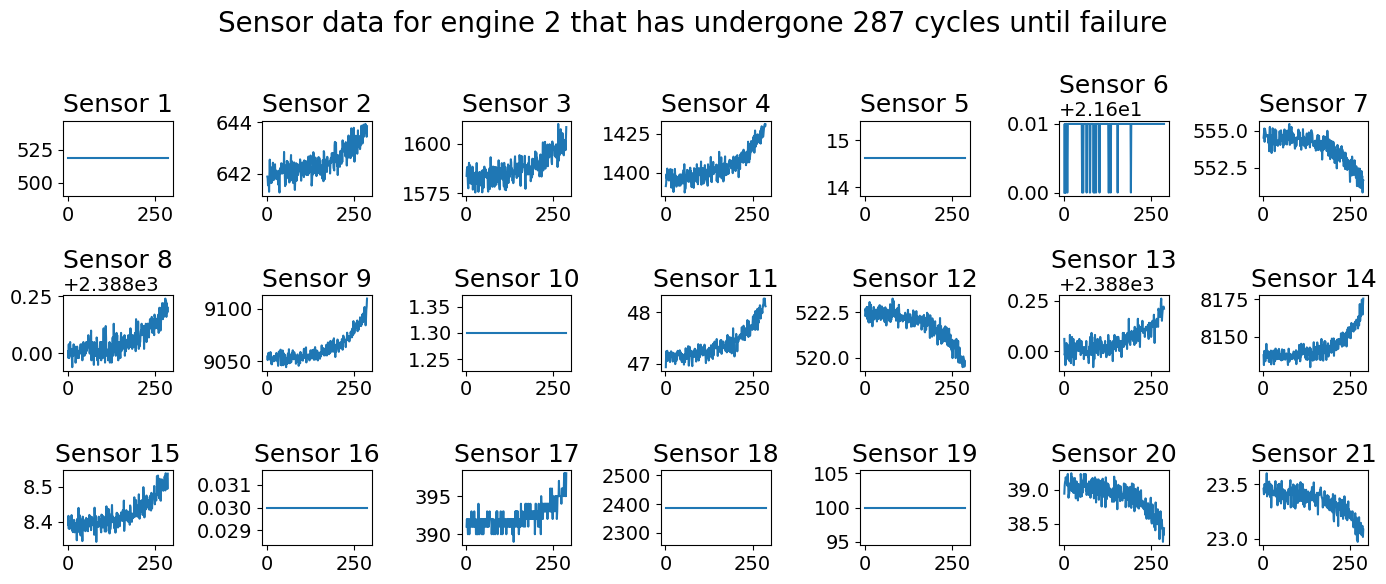

In [ ]:
# Select a C-MAPSS subset: uncomment one assignment only
dataName = 'FD001'
# dataName = 'FD003'

# Select the engine displayed in the example
ig = 2

import scipy.io as io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = DATA_ROOT / "CMAPSS"
file_path = data_dir / f"train_{dataName}.txt"

data = pd.read_csv(file_path, header=None, sep=r"\s+").values

# Data construction
eng_num = data[:, 0]  # Engine id
cyc = data[:, 1]  # Cycle
op = data[:, 2:5]  # Operating condition
sen = data[:, 5:26]  # Sensor data
eng, eng1 = np.unique(
    eng_num, return_index=True
)  # J includes 1st cycle in cumulative number of engine i
eng1 += 1
neng = len(eng)  # Number of engines to be used for training
ndata = len(data)  # Total number of data

plt.figure(figsize=(14, 6))  # Plot all the sensors data of engine #ig as an example
eol = int(cyc[eng_num == ig].max())

for i in range(21):
    plt.subplot(3, 7, i + 1)
    plt.plot(cyc[eng_num == ig], sen[eng_num == ig, i])
    plt.title("Sensor {}".format(i + 1))

plt.suptitle(
    "Sensor data for engine {} that has undergone {} cycles until failure".format(
        ig, eol
    ),
    fontsize=20,
)

plt.tight_layout(); plt.show()

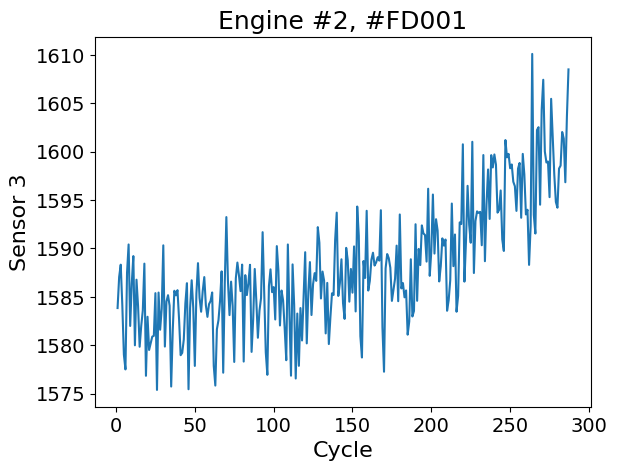

In [ ]:
# If necessary, plot specific sensors data of engine #ig with sensor id #ks

plt.figure()
ks = 2
plt.plot(cyc[eng_num == ig], sen[eng_num == ig, ks])
plt.ylabel("Sensor {}".format(ks + 1)); plt.xlabel("Cycle")
plt.title(f"Engine #{ig}, #{dataName}")
plt.show()

### EOL of all training engines

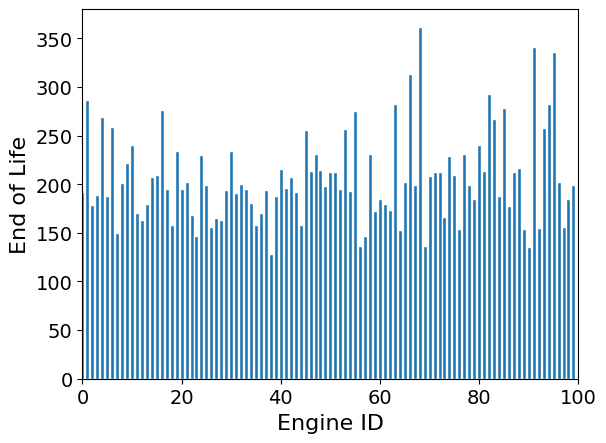

In [ ]:
# If necessary, plot EOL of all engines
plt.figure()
EOL = np.concatenate((np.diff(eng1), ndata - np.max(eng1)), axis=None)
plt.bar(np.arange(neng), EOL, edgecolor="white")
plt.xlabel("Engine ID"); plt.ylabel("End of Life"); plt.xlim(0, neng); plt.show()

### What is Spearman corr

  ID   X   Y  rank_X  rank_Y    d   d2
0  A  73  77     6.0     7.0 -1.0  1.0
1  B  76  78     5.0     6.0 -1.0  1.0
2  C  78  79     4.0     5.0 -1.0  1.0
3  D  65  80     7.0     4.0  3.0  9.0
4  E  86  86     2.0     3.0 -1.0  1.0
5  F  82  89     3.0     2.0  1.0  1.0
6  G  91  95     1.0     1.0  0.0  0.0

Sum of d^2 = 14
Spearman rho by original method    = 0.7500
Spearman rho by simplified formula = 0.7500
Spearman rho by scipy.spearmanr    = 0.7500


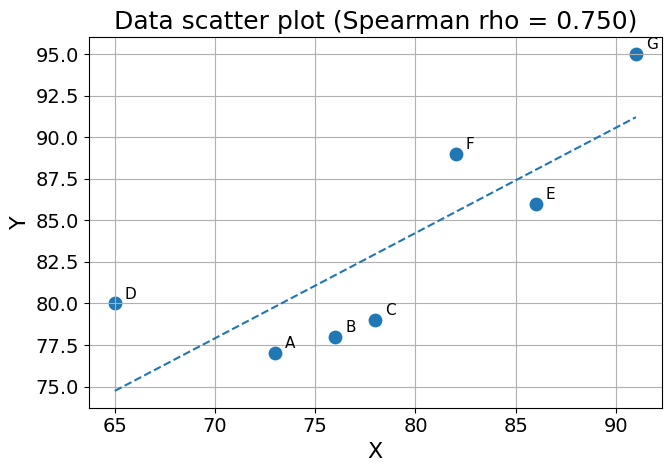

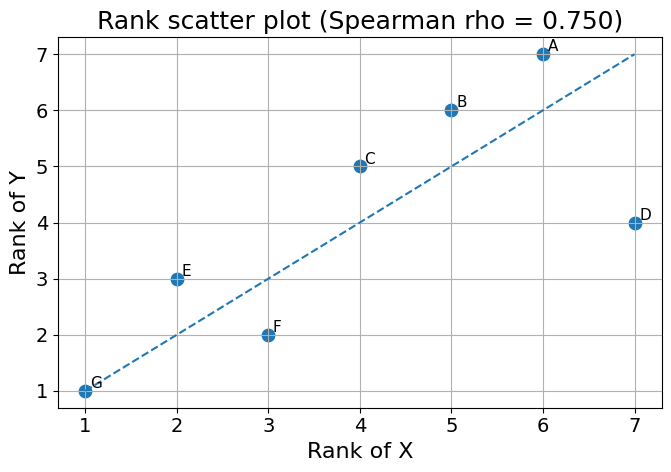

In [ ]:
# Spearman correlation is explained using a simple example
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, pearsonr, spearmanr

# Original data
data = pd.DataFrame(
    {
        "ID": ["A", "B", "C", "D", "E", "F", "G"],
        "X": [73, 76, 78, 65, 86, 82, 91],
        "Y": [77, 78, 79, 80, 86, 89, 95],
    }
)

# Rank calculation
# Rank 1 = highest value, consistent with the table
data["rank_X"] = rankdata(-data["X"], method="average")
data["rank_Y"] = rankdata(-data["Y"], method="average")

# Rank difference
data["d"] = data["rank_X"] - data["rank_Y"]
data["d2"] = data["d"] ** 2

# Method 1: original Spearman method
# Pearson correlation of the ranks
rho_original, _ = pearsonr(data["rank_X"], data["rank_Y"])

# Method 2: simplified formula
n = len(data)
sum_d2 = data["d2"].sum()
rho_simple = 1 - (6 * sum_d2) / (n * (n**2 - 1))

# Built-in check
rho_builtin, _ = spearmanr(data["X"], data["Y"])

# Print results
print(data)
print()
print(f"Sum of d^2 = {format_number(sum_d2, '.0f')}")
print(f"Spearman rho by original method    = {format_number(rho_original, '.4f')}")
print(f"Spearman rho by simplified formula = {format_number(rho_simple, '.4f')}")
print(f"Spearman rho by scipy.spearmanr    = {format_number(rho_builtin, '.4f')}")

# Plot 1: original x-y scatter
plt.figure(figsize=(7, 5))
plt.scatter(data["X"], data["Y"], s=80)

# Add point labels
for i in range(len(data)):
    plt.text(
        data.loc[i, "X"] + 0.5, data.loc[i, "Y"] + 0.3, data.loc[i, "ID"], fontsize=11
    )

# Optional guide line
coef = np.polyfit(data["X"], data["Y"], 1)
xfit = np.linspace(data["X"].min(), data["X"].max(), 100)
yfit = coef[0] * xfit + coef[1]
plt.plot(xfit, yfit, "--")

plt.xlabel("X"); plt.ylabel("Y")
plt.title(f"Data scatter plot (Spearman rho = {format_number(rho_original, '.3f')})")
plt.grid(True); plt.tight_layout(); plt.show()

# Plot 2: rank scatter
plt.figure(figsize=(7, 5))
plt.scatter(data["rank_X"], data["rank_Y"], s=80)

# Add point labels
for i in range(len(data)):
    plt.text(
        data.loc[i, "rank_X"] + 0.05,
        data.loc[i, "rank_Y"] + 0.05,
        data.loc[i, "ID"],
        fontsize=11,
    )

# Reference line y = x
rmin = min(data["rank_X"].min(), data["rank_Y"].min())
rmax = max(data["rank_X"].max(), data["rank_Y"].max())
plt.plot([rmin, rmax], [rmin, rmax], "--")

plt.xlabel("Rank of X"); plt.ylabel("Rank of Y")
plt.title(f"Rank scatter plot (Spearman rho = {format_number(rho_original, '.3f')})")
plt.grid(True); plt.tight_layout(); plt.show()

### Sensor selection
Selects sensors whose absolute Spearman correlation with cycle exceeds 0.5, calculated for each sensor using data from all training engines.

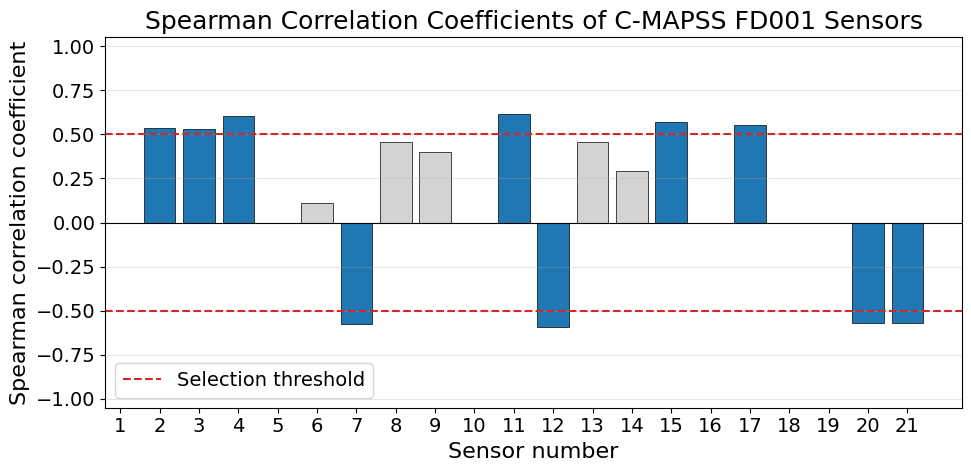

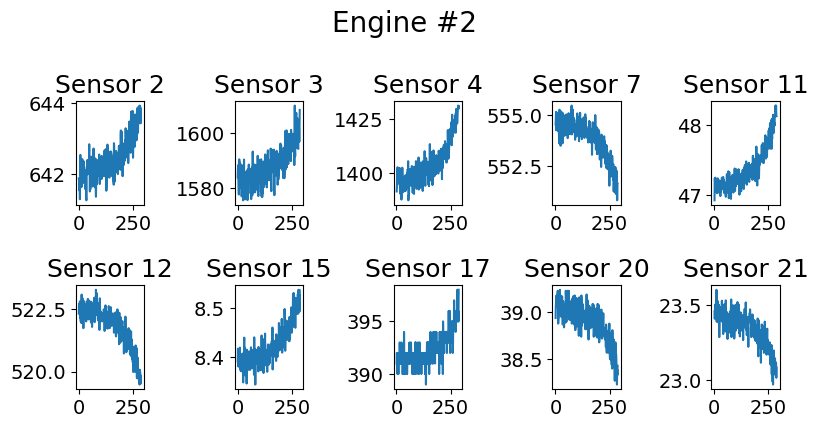

In [ ]:
# Preprocessing of training data

# Select sensors by Spearman correlation
cyc = np.reshape(cyc, (np.shape(cyc)[0], 1))
corrdata = pd.DataFrame(
    np.hstack([sen, cyc])
)  # 1~21 = Sen, 22 = cycselected sensors data
spval = np.array(corrdata.corr(method="spearman"))[-1, :-1]
selOrd = [i for (i, val) in enumerate(spval) if abs(val) > 0.5]
selSen = sen[:, selOrd]  # Selected sensors data

# Plot the pooled Spearman correlation of each sensor with cycle.
sensor_ids = np.arange(1, len(spval) + 1)
selected = np.abs(spval) > 0.5
colors = np.where(selected, "tab:blue", "lightgray")

plt.figure(figsize=(10, 5))
plt.bar(sensor_ids, spval, color=colors, edgecolor="black", linewidth=0.5)
plt.axhline(0.5, color="tab:red", linestyle="--", label="Selection threshold")
plt.axhline(-0.5, color="tab:red", linestyle="--")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(sensor_ids); plt.ylim(-1.05, 1.05); plt.xlabel("Sensor number")
plt.ylabel("Spearman correlation coefficient")
plt.title(f"Spearman Correlation Coefficients of C-MAPSS {dataName} Sensors")
plt.grid(axis="y", alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

# Plot selected sensors data of engine #ig
plt.figure(figsize=(8, 6))
for k in range(len(selOrd)):
    plt.subplot(3, 5, k + 1)
    ks = selOrd[k]
    plt.plot(cyc[eng_num == ig], selSen[eng_num == ig, k])
    plt.title("Sensor {}".format(ks + 1))
plt.suptitle("Engine #{}".format(ig), fontsize=20)
plt.tight_layout(); plt.show()

### Sensor selection another method
Computes Spearman correlations separately for each engine and selects sensors whose median correlation across engines exceeds 0.7 in absolute value.

In [ ]:
# Import NumPy as np
# Import Pandas as pd
# From SciPy.stats import spearmanr

# #  Inputs assumed
# # Eng_num : engine id, shape = (ndata,)
# # Cyc     : cycle, shape = (ndata,) or (ndata, 1)
# # Sen     : sensor data, shape = (ndata, 21)

# # Make sure cycle is 1-d
# cyc_1d = np.ravel(cyc)

# # Unique engine ids
# engine_ids = np.unique(eng_num)

# # Number of sensors
# n_sensors = sen.shape[1]

# # Storage for Spearman correlation
# # Rows    : engines
# # Columns : sensors
# sp_engine = np.full((len(engine_ids), n_sensors), np.nan)

# #  Compute Spearman correlation for each engine and each sensor for j, eid in
# enumerate(engine_ids):

# idx = eng_num == eid
# cyc_e = cyc_1d[idx]

# For i in range(n_sensors):

# sen_e = sen[idx, i]

# # Skip constant sensor signal because correlation is undefined
# If np.std(sen_e) == 0:
# Sp_engine[j, i] = np.nan
# Else:
# Rho, _ = spearmanr(cyc_e, sen_e)
# Sp_engine[j, i] = rho

# #  Aggregate across engines
# sp_mean = np.nanmean(sp_engine, axis=0)
# sp_median = np.nanmedian(sp_engine, axis=0)

# #  Sensor selection
# threshold = 0.7

# # Option 1: selection by mean absolute correlation
# selOrd_mean = [
# I for i, val in enumerate(sp_mean)
# If abs(val) > threshold
# ]

# # Option 2: selection by median absolute correlation
# selOrd_median = [
# I for i, val in enumerate(sp_median)
# If abs(val) > threshold
# ]

# #  Selected sensor data
# selSen_mean = sen[:, selOrd_mean]
# selSen_median = sen[:, selOrd_median]

# #  Print results
# print("Selected sensors by mean Spearman correlation:")
# print([i + 1 for i in selOrd_mean])

# print("\nSelected sensors by median Spearman correlation:")
# print([i + 1 for i in selOrd_median])

# selOrd = selOrd_median
# selSen = sen[:, selOrd] # finally selected sensors data

### Sensor normalization

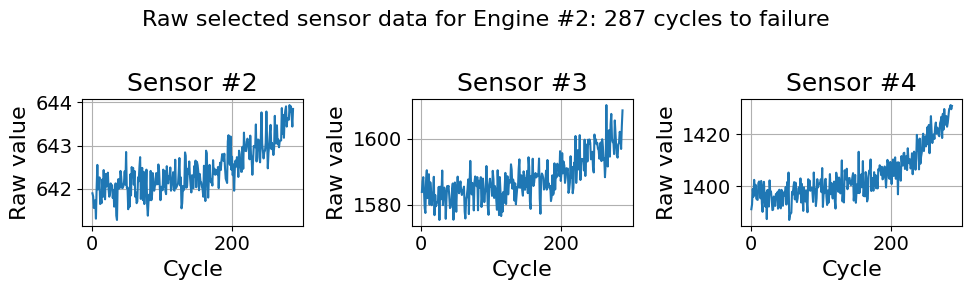

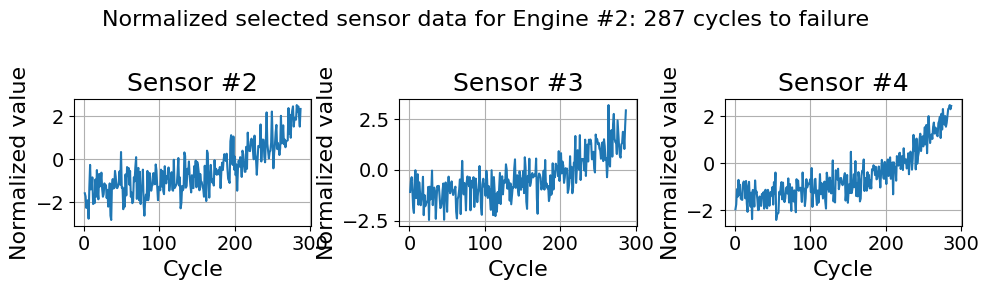

In [ ]:
# User settings: change these values to repeat the experiment
ig = 2  # Engine shown in the example plot

import numpy as np
import matplotlib.pyplot as plt

# Normalize selected sensors using all training engines

mu = np.mean(selSen, axis=0)
sigma = np.std(selSen, axis=0)

sigma_safe = sigma.copy()
sigma_safe[sigma_safe == 0] = 1

selSen0 = (selSen - mu) / sigma_safe

# Save training normalization parameters
mu_train = mu.copy()
sigma_train_safe = sigma_safe.copy()

# User settings

display_sensor_ids = [2, 3, 4]

# Convert display sensor numbers to positions inside selSen

display_pos = []
display_sid = []

for sid in display_sensor_ids:

    sidx = sid - 1

    if sidx in selOrd:
        display_pos.append(selOrd.index(sidx))
        display_sid.append(sid)
    else:
        print(f"Sensor #{sid} was not selected and will be skipped.")

# Extract selected engine data

idx = eng_num == ig

cyc_e = np.ravel(cyc[idx])

selSen_e = selSen[idx, :]
selSen0_e = selSen0[idx, :]

eol = int(cyc_e.max())

# Figure 1: raw selected sensor signals

plt.figure(figsize=(10, 3))

for k, pos in enumerate(display_pos):

    sid = display_sid[k]

    plt.subplot(1, len(display_pos), k + 1)
    plt.plot(cyc_e, selSen_e[:, pos])
    plt.title(f"Sensor #{sid}")
    plt.xlabel("Cycle"); plt.ylabel("Raw value"); plt.grid(True)

plt.suptitle(
    f"Raw selected sensor data for Engine #{ig}: {eol} cycles to failure", fontsize=16
)

plt.tight_layout(); plt.show()

# Figure 2: normalized selected sensor signals

plt.figure(figsize=(10, 3))

for k, pos in enumerate(display_pos):

    sid = display_sid[k]

    plt.subplot(1, len(display_pos), k + 1)
    plt.plot(cyc_e, selSen0_e[:, pos])
    plt.title(f"Sensor #{sid}")
    plt.xlabel("Cycle"); plt.ylabel("Normalized value"); plt.grid(True)

plt.suptitle(
    f"Normalized selected sensor data for Engine #{ig}: {eol} cycles to failure",
    fontsize=16,
)

plt.tight_layout(); plt.show()

### Sensor smoothing

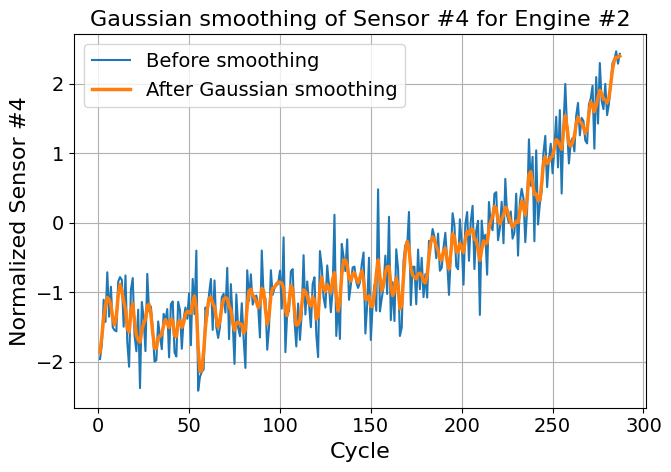

In [ ]:
# User settings: change these values to repeat the experiment
gauss_sigma = 1.0  # Width of the Gaussian kernel
kernel_size = 5  # Total number of data points in the Gaussian kernel
ig = 2  # Engine id to display
display_sensor_id = 4  # Actual sensor number, not Python index

import numpy as np
import matplotlib.pyplot as plt

# User settings

# Must be an odd number

# Gaussian smoothing function

# Apply Gaussian smoothing to selected and normalized sensors
# Engine by engine

selSen_smooth = np.zeros_like(selSen0)

for eid in np.unique(eng_num):

    idx_e = eng_num == eid

    for j in range(selSen0.shape[1]):

        selSen_smooth[idx_e, j] = gaussian_smooth_1d(
            selSen0[idx_e, j], gauss_sigma=gauss_sigma, kernel_size=kernel_size
        )

# Plot before and after smoothing

display_sensor_index = display_sensor_id - 1

if display_sensor_index not in selOrd:
    raise ValueError(
        f"Sensor #{display_sensor_id} was not selected by Spearman correlation."
    )

# Position of the displayed sensor inside selSen0
k_display = selOrd.index(display_sensor_index)

idx_display = eng_num == ig

cyc_e = np.ravel(cyc[idx_display])

y_before = selSen0[idx_display, k_display]
y_after = selSen_smooth[idx_display, k_display]

eol = int(cyc_e.max())

plt.figure(figsize=(7, 5))

plt.plot(cyc_e, y_before, label="Before smoothing", linewidth=1.5)

plt.plot(cyc_e, y_after, label="After Gaussian smoothing", linewidth=2.5)

plt.xlabel("Cycle")
plt.ylabel(f"Normalized Sensor #{display_sensor_id}")

plt.title(
    f"Gaussian smoothing of Sensor #{display_sensor_id} for Engine #{ig}", fontsize=16
)

plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()

### RUL definition

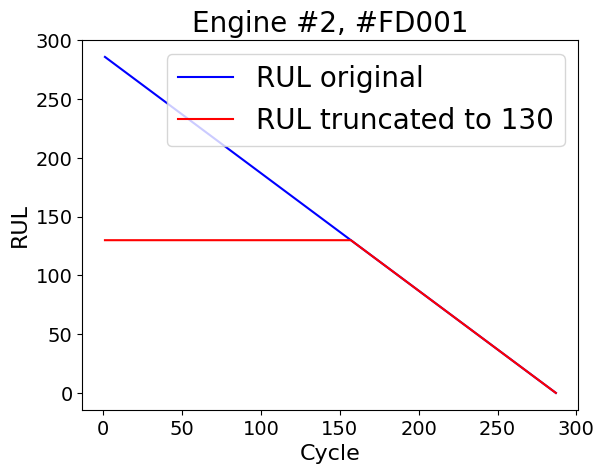

In [ ]:
# Define RUL such that it decreases from (eol-1) at 1st to 0 at EOL.
rul = np.concatenate(
    [-cyc[eng_num == i] + np.max(cyc[eng_num == i]) for i in range(1, neng + 1)]
)

plt.figure()  # Plot rul original of engine #ig.
plt.plot(cyc[eng_num == ig], rul[eng_num == ig], "b")

EOL = np.concatenate((np.diff(eng1), ndata - np.max(eng1)), axis=None)
EOLmin = np.min(EOL)
cmin = round(EOLmin / 10) * 10  # Minimum rul rounded to order of 10.
rul = np.where(cmin < rul, cmin, rul)  # Truncate rul at cmin.

plt.plot(cyc[eng_num == ig], rul[eng_num == ig], "r")
plt.legend(["RUL original", f"RUL truncated to {cmin}"], fontsize=20); plt.ylabel("RUL")
plt.xlabel("Cycle")
plt.title(f"Engine #{ig}, #{dataName}", fontsize=20)
plt.show()

# MLP in prognosis

### ANN training

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
patience = 6  # Epochs without validation improvement
maximum_epochs = 1000  # Maximum training epochs
random_state = 0  # Random seed for reproducible splitting

import time

# Set the epoch reporting interval

# Neural training settings

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping

# Fix random states and use deterministic TensorFlow operations.
tf.keras.utils.set_random_seed(random_state)
tf.config.experimental.enable_op_determinism()

# Purpose: build an MLP after splitting complete engines into training and validation sets.
# Input: X, y, engine_no, train_ratio, random_state.
# Output: returned (model, x_train, y_train, x_valid, y_valid, train_engines, valid_engines).
# Used in: MLP in prognosis.
def model_make(X, y, engine_no, train_ratio=0.75, random_state=0):
    # Split engine ids to keep all records from each engine in one set.
    engine_ids = np.unique(engine_no)
    train_engines, valid_engines = train_test_split(
        engine_ids,
        train_size=train_ratio,
        test_size=1 - train_ratio,
        shuffle=True,
        random_state=random_state,
    )
    idx_train, idx_valid = np.isin(engine_no, train_engines), np.isin(
        engine_no, valid_engines
    )
    x_train, y_train = X[idx_train], y[idx_train]
    x_valid, y_valid = X[idx_valid], y[idx_valid]

    # Estimate RUL from the sensor values measured at the current cycle.
    inputs = tf.keras.layers.Input(shape=(X.shape[1],))
    hidden = tf.keras.layers.Dense(30, activation="tanh")(inputs)
    hidden = tf.keras.layers.BatchNormalization()(hidden)
    outputs = tf.keras.layers.Dense(1)(hidden)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="mse")
    return model, x_train, y_train, x_valid, y_valid, train_engines, valid_engines

X, y = selSen_smooth, rul
mdl, x_train, y_train, x_valid, y_valid, train_engines, valid_engines = model_make(
    X, y, eng_num, train_ratio=0.75, random_state=random_state
)

early_stopping = EarlyStopping(
    monitor="val_loss", mode="min", patience=patience, restore_best_weights=True
)
start_time = time.perf_counter()

# Report the model and data before training
show_model_info(mdl, x_train, x_valid)
training_started = time.perf_counter()
history = mdl.fit(
    x_train,
    y_train,
    epochs=maximum_epochs,
    validation_data=(x_valid, y_valid),
    callbacks=[early_stopping] + [training_progress(progress_interval)],
    verbose=0,
)
report_training(history, training_started)

training_time_mlp = time.perf_counter() - start_time
print(f"MLP training time = {format_number(training_time_mlp / 60, '.2f')} min")

MLP training time = 1.10 min


### Plot train val loss & R2

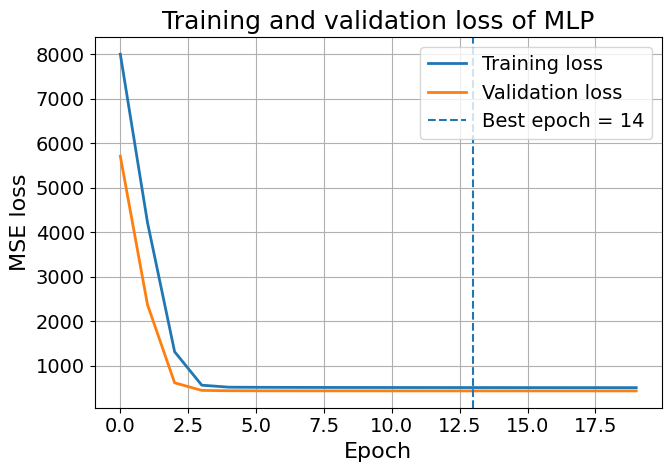

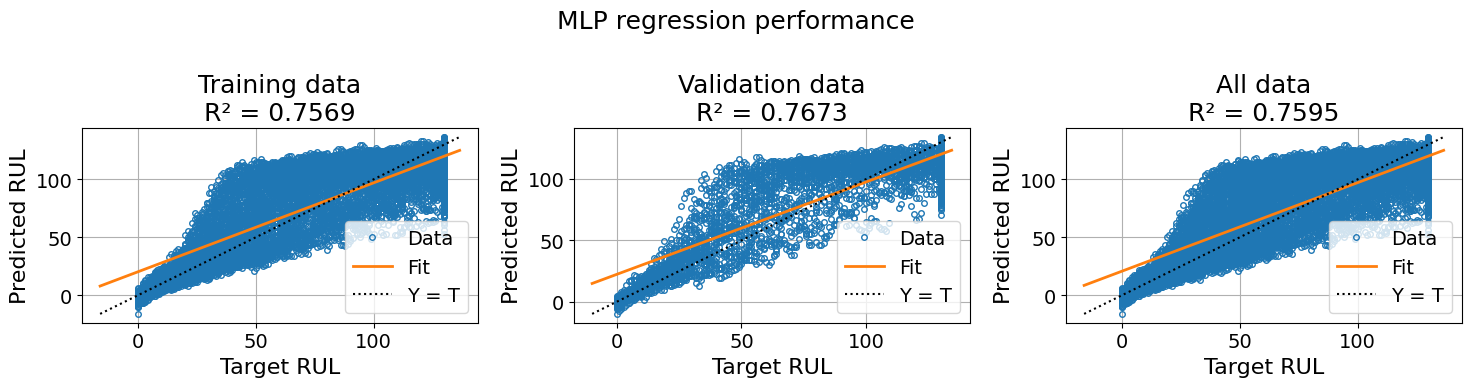

Training RMSE   = 21.4240
Validation RMSE = 20.9439
All-data RMSE   = 21.3036


In [ ]:
# Plot training and validation losses.
train_loss, valid_loss = history.history["loss"], history.history["val_loss"]
best_epoch = np.argmin(valid_loss) + 1

plt.figure(figsize=(7, 5))
plt.plot(train_loss, label="Training loss", linewidth=2)
plt.plot(valid_loss, label="Validation loss", linewidth=2)
plt.axvline(
    best_epoch - 1, linestyle="--", linewidth=1.5, label=f"Best epoch = {best_epoch}"
)
plt.xlabel("Epoch"); plt.ylabel("MSE loss")
plt.title("Training and validation loss of MLP"); plt.grid(True); plt.legend()
plt.tight_layout(); plt.show()

# Purpose: plot predicted versus target RUL and report the coefficient of determination.
# Input: ax, y_true, y_pred, title.
# Output: updated state or displayed result; no return value.
# Used in: MLP in prognosis.
def plot_regression_r2(ax, y_true, y_pred, title):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    r2 = r2_score(y_true, y_pred)
    a, b = np.polyfit(y_true, y_pred, 1)
    limits = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    line = np.linspace(*limits, 100)
    ax.plot(y_true, y_pred, "o", markerfacecolor="none", markersize=4, label="Data")
    ax.plot(line, a * line + b, linewidth=2, label="Fit")
    ax.plot(line, line, "k:", linewidth=1.5, label="Y = T")
    ax.set(
        xlabel="Target RUL",
        ylabel="Predicted RUL",
        title=f"{title}\nR² = {format_number(r2, '.4f')}",
    )
    ax.grid(True); ax.legend()

y_train_pred = mdl.predict(x_train, verbose=0).ravel()
y_valid_pred = mdl.predict(x_valid, verbose=0).ravel()
y_all_pred = mdl.predict(X, verbose=0).ravel()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_regression_r2(axes[0], y_train, y_train_pred, "Training data")
plot_regression_r2(axes[1], y_valid, y_valid_pred, "Validation data")
plot_regression_r2(axes[2], y, y_all_pred, "All data")
plt.suptitle("MLP regression performance")
plt.tight_layout(); plt.show()

rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_valid = np.sqrt(mean_squared_error(y_valid, y_valid_pred))
rmse_all = np.sqrt(mean_squared_error(y, y_all_pred))
print(f"Training RMSE   = {format_number(rmse_train, '.4f')}")
print(f"Validation RMSE = {format_number(rmse_valid, '.4f')}")
print(f"All-data RMSE   = {format_number(rmse_all, '.4f')}")

### Predict RUL for  training

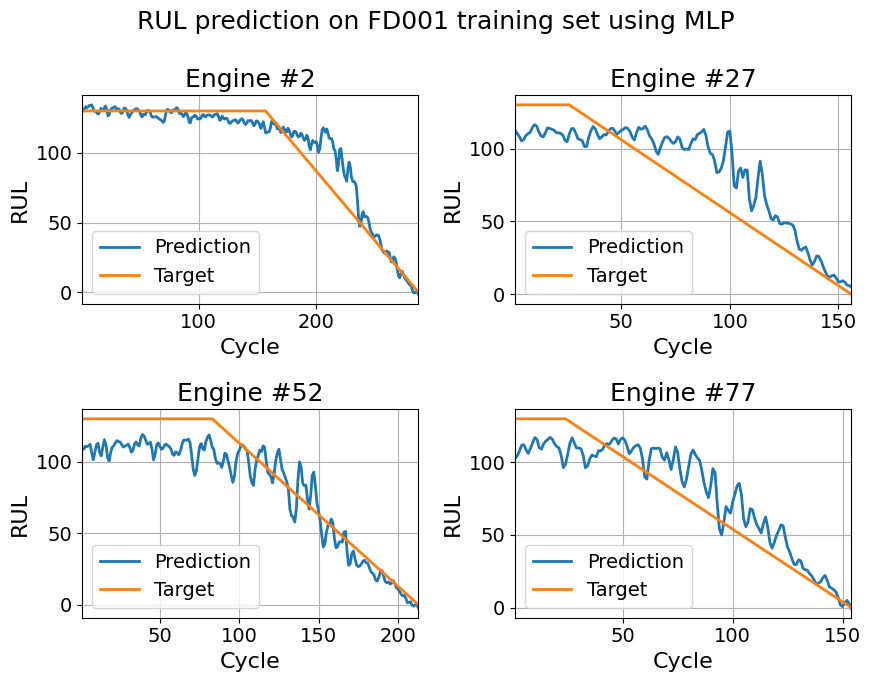

In [ ]:
# Plot RUL predictions for selected training engines.
display_engines = [2, 27, 52, 77]
plt.figure(figsize=(9, 7))

for panel, eid in enumerate(display_engines, start=1):
    idx = eng_num == eid
    cyc_e, rul_e = np.ravel(cyc[idx]), np.ravel(rul[idx])
    pred_e = mdl.predict(selSen_smooth[idx], verbose=0).ravel()

    plt.subplot(2, 2, panel)
    plt.plot(cyc_e, pred_e, label="Prediction", linewidth=2)
    plt.plot(cyc_e, rul_e, label="Target", linewidth=2)
    plt.title(f"Engine #{eid}")
    plt.xlabel("Cycle"); plt.ylabel("RUL"); plt.xlim(cyc_e.min(), cyc_e.max())
    plt.grid(True); plt.legend()

plt.suptitle(f"RUL prediction on {dataName} training set using MLP")
plt.tight_layout(); plt.show()

### Load test set

In [ ]:
import pandas as pd

# Load the selected-subset test records and final true RUL values.
data_dir = DATA_ROOT / "CMAPSS"
test_data = pd.read_csv(data_dir / f"test_{dataName}.txt", header=None, sep=r"\s+").values
true_rul_final = pd.read_csv(
    data_dir / f"RUL_{dataName}.txt", header=None, sep=r"\s+"
).values.ravel()

eng_num_test, cyc_test = test_data[:, 0], test_data[:, 1]
op_test, sen_test = test_data[:, 2:5], test_data[:, 5:26]
engine_ids_test = np.unique(eng_num_test)
n_test_engines = len(engine_ids_test)

### Process sensor test set

In [ ]:
# Apply training statistics and smooth each test engine independently.
selSen_test = sen_test[:, selOrd]
selSen_test_norm = (selSen_test - mu_train) / sigma_train_safe
selSen_test_smooth = np.zeros_like(selSen_test_norm)

for eid in engine_ids_test:
    idx = eng_num_test == eid
    for sensor in range(selSen_test_norm.shape[1]):
        selSen_test_smooth[idx, sensor] = gaussian_smooth_1d(
            selSen_test_norm[idx, sensor],
            gauss_sigma=gauss_sigma,
            kernel_size=kernel_size,
        )

### Predict RUL for test

RMSE = 20.5014
Score = 1044.5697


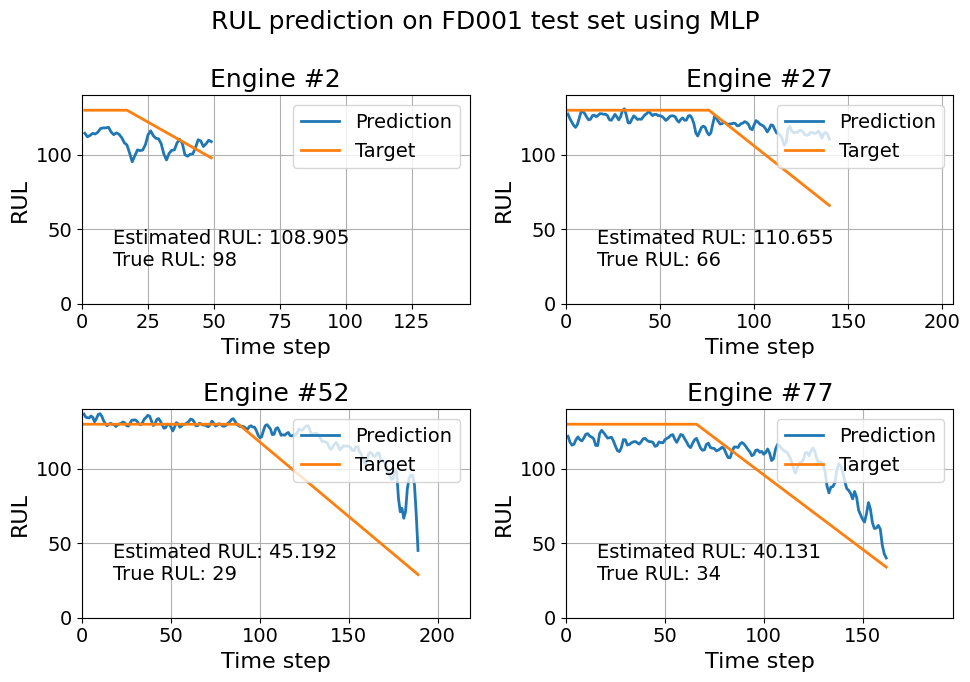

In [ ]:
# Predict every test record and retain the final prediction for each engine.
# Report the independent test input before prediction
print("Test samples:", len(selSen_test_smooth))

pred_test_all = mdl.predict(selSen_test_smooth, verbose=0).ravel()
pred_rul_final = np.array(
    [pred_test_all[np.where(eng_num_test == eid)[0][-1]] for eid in engine_ids_test]
)

# Calculate RMSE and the asymmetric C-MAPSS score.
errors = pred_rul_final - true_rul_final
rmse = np.sqrt(np.mean(errors**2))
score_each = np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
score = np.sum(score_each)
print(f"RMSE = {format_number(rmse, '.4f')}")
print(f"Score = {format_number(score, '.4f')}")

# Plot predictions for selected test engines.
plt.figure(figsize=(10, 7))
for panel, eid in enumerate(display_engines, start=1):
    idx = eng_num_test == eid
    cyc_e, pred_e = np.ravel(cyc_test[idx]), pred_test_all[idx]
    position = np.where(engine_ids_test == eid)[0][0]
    true_final = true_rul_final[position]
    eol_cycle = cyc_e.max() + true_final
    true_rul_e = np.minimum(true_final + cyc_e.max() - cyc_e, cmin)

    plt.subplot(2, 2, panel)
    plt.plot(cyc_e, pred_e, label="Prediction", linewidth=2)
    plt.plot(cyc_e, true_rul_e, label="Target", linewidth=2)
    plt.xlabel("Time step"); plt.ylabel("RUL")
    plt.title(f"Engine #{eid}")
    plt.xlim(0, eol_cycle); plt.ylim(0, float(cmin) + 10)
    plt.text(
        0.08,
        0.18,
        f"Estimated RUL: {format_number(pred_e[-1], '.3f')}\nTrue RUL:"
        f" {format_number(true_final, '.0f')}",
        transform=plt.gca().transAxes,
        fontsize=14,
    )
    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(f"RUL prediction on {dataName} test set using MLP")
plt.tight_layout(); plt.show()

# CNN in prognosis

### Functions

In [ ]:
# CNN model construction: 1D or 2D CNN

# Purpose: build a 1D or 2D C-MAPSS convolutional RUL model.
# Input: window_length, n_features, cnn_type, dropout_rate.
# Output: returned model.
# Used in: CNN in prognosis; 1D CNN RUL prediction using 10% of training engines.
def build_cnn_model(window_length, n_features, cnn_type, dropout_rate=0.2):

    if cnn_type == "1d":

        input_layer = tf.keras.layers.Input(shape=(window_length, n_features))

        x = tf.keras.layers.Conv1D(
            filters=32, kernel_size=5, padding="valid", activation="relu"
        )(input_layer)

        x = tf.keras.layers.BatchNormalization()(x)

        x = tf.keras.layers.Conv1D(
            filters=64, kernel_size=3, padding="valid", activation="relu"
        )(x)

        x = tf.keras.layers.BatchNormalization()(x)

        x = tf.keras.layers.Dropout(dropout_rate)(x)

        x = tf.keras.layers.GlobalAveragePooling1D()(x)

    elif cnn_type == "2d":

        input_layer = tf.keras.layers.Input(shape=(window_length, n_features, 1))

        x = tf.keras.layers.Conv2D(
            filters=32, kernel_size=(5, 3), padding="valid", activation="relu"
        )(input_layer)

        x = tf.keras.layers.BatchNormalization()(x)

        x = tf.keras.layers.Conv2D(
            filters=64, kernel_size=(3, 3), padding="valid", activation="relu"
        )(x)

        x = tf.keras.layers.BatchNormalization()(x)

        x = tf.keras.layers.Dropout(dropout_rate)(x)

        x = tf.keras.layers.GlobalAveragePooling2D()(x)

    else:
        raise ValueError("cnn_type must be either '1d' or '2d'.")

    x = tf.keras.layers.Dense(30, activation="tanh")(x)

    output = tf.keras.layers.Dense(1, activation="linear")(x)

    model = tf.keras.Model(inputs=input_layer, outputs=output)

    model.compile(optimizer="adam", loss="mse", metrics=["mse"])

    return model

### CNN training by enginewise split

In [ ]:
# Select the CNN input format: uncomment one assignment only
cnn_type = '1d'
# cnn_type = '2d'

# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
window_length = 30  # Cycles in each complete input window
batch_size = 32  # Samples per training batch
max_epochs = 1000  # Maximum training epochs
patience = 10  # Epochs without validation improvement
nrep_cnn = 1

import time

# Set the epoch reporting interval

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping
from tqdm import tqdm
import time

# Reproducibility
tf.keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()

# Training settings

# Input data must be the same preprocessed data
# Selected + normalized + smoothed

X_row = selSen_smooth
y_row = rul

# Convert row-wise data to sequence data
# X_seq, y_seq, eng_seq, cyc_seq = make_sequence_data(
X_seq, y_seq, eng_seq, cyc_seq = make_sequence_data_no_padding(
    X_row, y_row, eng_num, cyc, window_length=window_length
)

# Select CNN input format: 1D or 2D CNN

if cnn_type == "1d":
    # X_seq shape = (samples, window_length, number_of_sensors)
    pass

elif cnn_type == "2d":
    # X_seq shape = (samples, window_length, number_of_sensors, 1)
    X_seq = X_seq[..., np.newaxis]

else:
    raise ValueError("cnn_type must be either '1d' or '2d'.")

print("CNN type:", cnn_type)
print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)

# Train repeated CNN models

cnn_models = []
cnn_histories = []
cnn_split_data = []

start_time = time.perf_counter()

for rep in tqdm(range(nrep_cnn)):

    engine_ids = np.unique(eng_seq)

    train_engines, valid_engines = train_test_split(
        engine_ids, train_size=0.75, test_size=0.25, shuffle=True, random_state=rep
    )

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)

    x_train_seq = X_seq[idx_train]
    y_train_seq = y_seq[idx_train]

    x_valid_seq = X_seq[idx_valid]
    y_valid_seq = y_seq[idx_valid]

    model_cnn = build_cnn_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        cnn_type=cnn_type,
        dropout_rate=0.2,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", mode="min", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_cnn, x_train_seq, x_valid_seq)
    training_started = time.perf_counter()
    history = model_cnn.fit(
        x_train_seq,
        y_train_seq,
        batch_size=batch_size,
        epochs=max_epochs,
        validation_data=(x_valid_seq, y_valid_seq),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    cnn_models.append(model_cnn)
    cnn_histories.append(history)

    cnn_split_data.append(
        {
            "x_train": x_train_seq,
            "y_train": y_train_seq,
            "x_valid": x_valid_seq,
            "y_valid": y_valid_seq,
            "train_engines": train_engines,
            "valid_engines": valid_engines,
        }
    )
training_time_cnn = time.perf_counter() - start_time
print(
    f"{cnn_type.upper()} CNN training time ="
    f" {format_number(training_time_cnn / 60, '.2f')} min"
)

CNN type: 1d
X_seq shape: (17731, 30, 10)
y_seq shape: (17731,)


100%|██████████| 1/1 [01:48<00:00, 108.55s/it]

1D CNN training time = 1.81 min


### Plot train val loss & R2

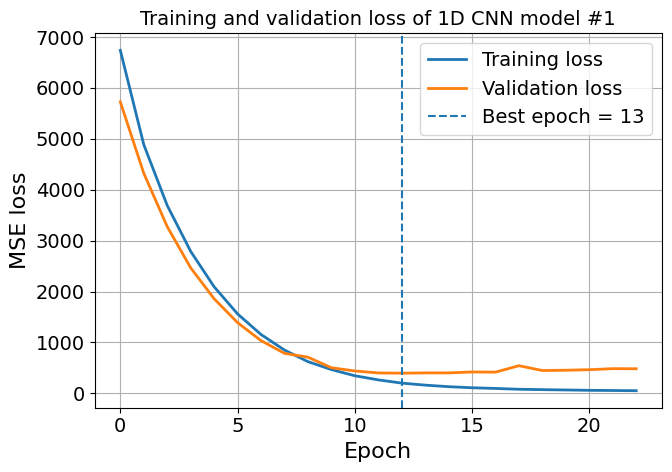

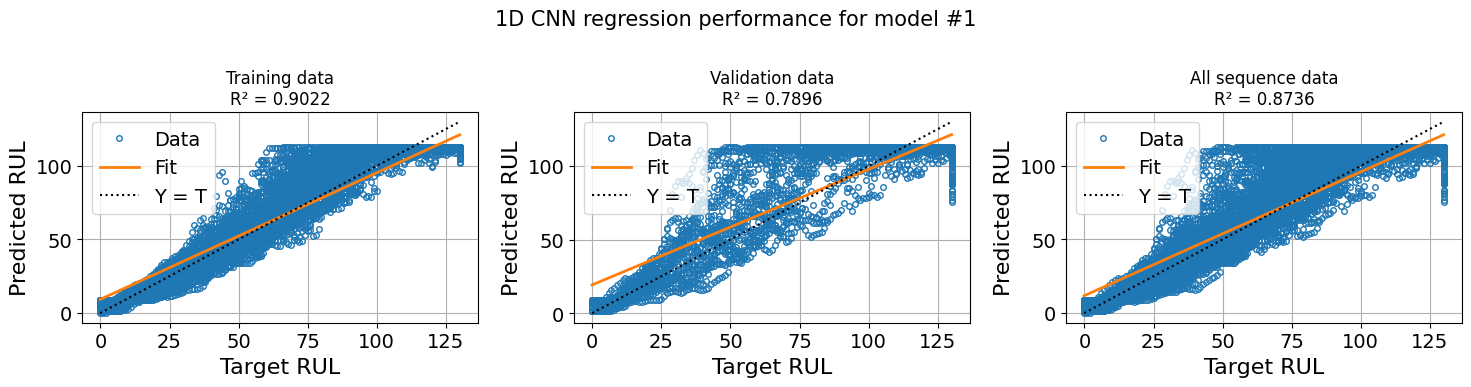

1D CNN model #1
  Training RMSE   = 13.5569
  Validation RMSE = 19.8831
  All-data RMSE   = 15.4084

Average RMSE over repeated 1D CNN models
  Training RMSE   = 13.5569
  Validation RMSE = 19.8831
  All-data RMSE   = 15.4084


In [ ]:
# Plot training and validation loss

model_id = 0

history = cnn_histories[model_id]
train_loss = history.history["loss"]
valid_loss = history.history["val_loss"]
best_epoch = np.argmin(valid_loss) + 1

plt.figure(figsize=(7, 5))

plt.plot(train_loss, label="Training loss", linewidth=2)

plt.plot(valid_loss, label="Validation loss", linewidth=2)

plt.axvline(
    best_epoch - 1, linestyle="--", linewidth=1.5, label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch")

plt.ylabel("MSE loss")

plt.title(
    f"Training and validation loss of {cnn_type.upper()} CNN model #{model_id + 1}",
    fontsize=14,
)

plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()

from sklearn.metrics import r2_score
import numpy as np
import matplotlib.pyplot as plt

# R2 regression plot function

# R2 regression plots for CNN
# Training, validation, and all sequence data

model_id = 0

model_cnn = cnn_models[model_id]

# Training and validation data used for this CNN model
x_train_seq = cnn_split_data[model_id]["x_train"]
y_train_seq = cnn_split_data[model_id]["y_train"]

x_valid_seq = cnn_split_data[model_id]["x_valid"]
y_valid_seq = cnn_split_data[model_id]["y_valid"]

# Prediction
y_train_pred = model_cnn.predict(x_train_seq, verbose=0).ravel()

y_valid_pred = model_cnn.predict(x_valid_seq, verbose=0).ravel()

y_all_pred = model_cnn.predict(X_seq, verbose=0).ravel()

# Combined R2 regression plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_regression_r2_subplot(axes[0], y_train_seq, y_train_pred, title="Training data")

plot_regression_r2_subplot(axes[1], y_valid_seq, y_valid_pred, title="Validation data")

plot_regression_r2_subplot(axes[2], y_seq, y_all_pred, title="All sequence data")

plt.suptitle(
    f"{cnn_type.upper()} CNN regression performance for model #{model_id + 1}",
    fontsize=15,
)

plt.tight_layout(); plt.show()

from sklearn.metrics import mean_squared_error
import numpy as np

# RMSE calculation for CNN
# Training, validation, and all sequence data

rmse_train_list = []
rmse_valid_list = []
rmse_all_list = []

for model_id in range(nrep_cnn):

    model = cnn_models[model_id]

    # --------------------------------------------------------
    # Training and validation data used for this CNN model
    # --------------------------------------------------------
    x_train = cnn_split_data[model_id]["x_train"]
    y_train = cnn_split_data[model_id]["y_train"]

    x_valid = cnn_split_data[model_id]["x_valid"]
    y_valid = cnn_split_data[model_id]["y_valid"]

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    y_train_pred = model.predict(x_train, verbose=0).ravel()

    y_valid_pred = model.predict(x_valid, verbose=0).ravel()

    y_all_pred = model.predict(
        X_seq,  # 1D CNN
        # X_seq_2d, # 2d CNN
        verbose=0,
    ).ravel()

    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------
    rmse_train = np.sqrt(mean_squared_error(np.ravel(y_train), y_train_pred))

    rmse_valid = np.sqrt(mean_squared_error(np.ravel(y_valid), y_valid_pred))

    rmse_all = np.sqrt(mean_squared_error(np.ravel(y_seq), y_all_pred))

    rmse_train_list.append(rmse_train)
    rmse_valid_list.append(rmse_valid)
    rmse_all_list.append(rmse_all)

    print(f"{cnn_type.upper()} CNN model #{model_id + 1}")
    print(f"  Training RMSE   = {format_number(rmse_train, '.4f')}")
    print(f"  Validation RMSE = {format_number(rmse_valid, '.4f')}")
    print(f"  All-data RMSE   = {format_number(rmse_all, '.4f')}")
    print()

# Average RMSE over repeated CNN models

mean_rmse_train = np.mean(rmse_train_list)
mean_rmse_valid = np.mean(rmse_valid_list)
mean_rmse_all = np.mean(rmse_all_list)

print(f"Average RMSE over repeated {cnn_type.upper()} CNN models")
print(f"  Training RMSE   = {format_number(mean_rmse_train, '.4f')}")
print(f"  Validation RMSE = {format_number(mean_rmse_valid, '.4f')}")
print(f"  All-data RMSE   = {format_number(mean_rmse_all, '.4f')}")

### Predict RUL for training

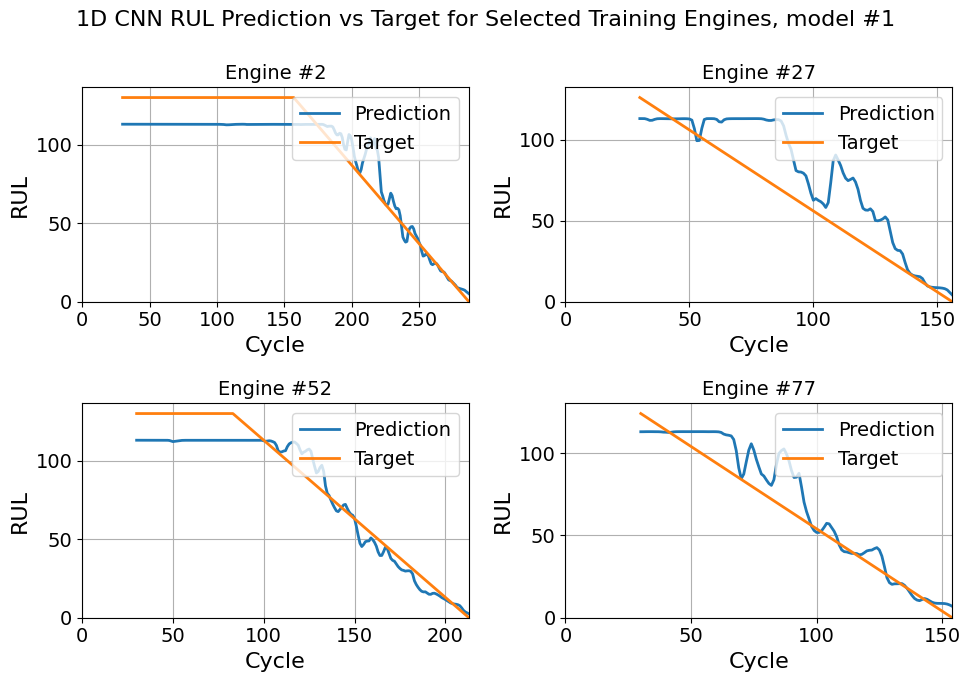

In [ ]:
# Plot RUL prediction vs target for selected training engines

display_engines = [2, 27, 52, 77]

model_id = 0

model_cnn = cnn_models[model_id]

plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):

    idx = eng_seq == eid

    cyc_e = cyc_seq[idx]
    X_e = X_seq[idx, :, :]
    y_true_e = y_seq[idx]
    y_pred_e = model_cnn.predict(X_e, verbose=0).ravel()

    order = np.argsort(cyc_e)
    cyc_e = cyc_e[order]
    y_true_e = y_true_e[order]
    y_pred_e = y_pred_e[order]
    eol = int(cyc_e.max())

    plt.subplot(2, 2, ii)

    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)

    plt.plot(cyc_e, y_true_e, label="Target", linewidth=2)

    plt.title(f"Engine #{int(eid)}", fontsize=14)

    plt.xlabel("Cycle"); plt.ylabel("RUL"); plt.xlim(0, eol); plt.ylim(bottom=0)
    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(
    f"{cnn_type.upper()} CNN RUL Prediction vs Target for Selected Training Engines,"
    f" model #{model_id + 1}",
    fontsize=16,
)
plt.tight_layout()

plt.show()

### Load test set

In [ ]:
# Use the C-MAPSS subset selected in the training-data cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the matching test set

data_dir = DATA_ROOT / "CMAPSS"

test_file = data_dir / f"test_{dataName}.txt"
rul_file = data_dir / f"RUL_{dataName}.txt"

# Load test data and true final RUL

test_data = pd.read_csv(test_file, header=None, sep=r"\s+").values

true_rul_final = pd.read_csv(rul_file, header=None, sep=r"\s+").values.ravel()

# Test data construction

eng_num_test = test_data[:, 0]
cyc_test = test_data[:, 1]
op_test = test_data[:, 2:5]
sen_test = test_data[:, 5:26]

engine_ids_test = np.unique(eng_num_test)
n_test_engines = len(engine_ids_test)

### Process sensor test set

In [ ]:
# Normalize test selected sensors using training mean and std

selSen_test = sen_test[:, selOrd]
selSen_test_norm = (selSen_test - mu_train) / sigma_train_safe

# Gaussian smoothing of test selected sensors
# Engine by engine

# gauss_sigma = 1.0, kernel_size = 5 should be already defined previously.
selSen_test_smooth = np.zeros_like(selSen_test_norm)

for eid in engine_ids_test:

    idx_e = eng_num_test == eid

    for j in range(selSen_test_norm.shape[1]):

        selSen_test_smooth[idx_e, j] = gaussian_smooth_1d(
            selSen_test_norm[idx_e, j], gauss_sigma=gauss_sigma, kernel_size=kernel_size
        )

### Predict RUL for test

CNN type: 1d
Model input shape: (None, 30, 10)
X_test_seq shape: (10196, 30, 10)
y_test_seq shape: (10196,)
FD001 test RMSE = 20.5542
FD001 test Score = 1559.6124


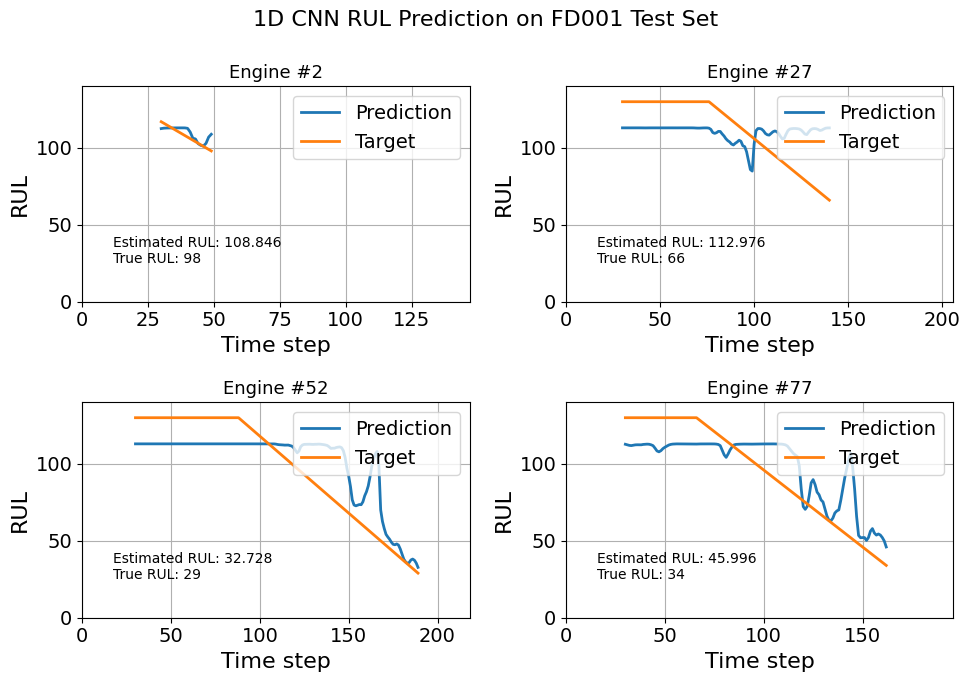

In [ ]:
display_engines = [2, 27, 52, 77]

# Reconstruct row-wise true RUL for test set

rul_test_row = np.zeros_like(cyc_test)

for i, eid in enumerate(engine_ids_test):

    idx_e = eng_num_test == eid
    cyc_e = cyc_test[idx_e]
    max_cycle_e = cyc_e.max()
    final_rul_e = true_rul_final[i]
    rul_test_row[idx_e] = final_rul_e + max_cycle_e - cyc_e

# Convert test data to CNN sequence data

# X_test_seq, y_test_seq, eng_test_seq, cyc_test_seq = make_sequence_data(
X_test_seq, y_test_seq, eng_test_seq, cyc_test_seq = make_sequence_data_no_padding(
    selSen_test_smooth,
    rul_test_row,
    eng_num_test,
    cyc_test,
    window_length=window_length,
)

if cnn_type == "1d":
    pass

elif cnn_type == "2d":
    X_test_seq = X_test_seq[..., np.newaxis]

else:
    raise ValueError("cnn_type must be either '1d' or '2d'.")

print("CNN type:", cnn_type)
print("Model input shape:", model_cnn.input_shape)
print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

# Predict RUL on test set

use_ensemble_median = True

if use_ensemble_median and len(cnn_models) > 1:

    pred_all_models = np.zeros((len(cnn_models), X_test_seq.shape[0]))

    for rep, mdl in enumerate(cnn_models):

        # Report the independent test input before prediction
        print("Test samples:", len(X_test_seq))

        pred_tmp = mdl.predict(X_test_seq, verbose=0).ravel()

        pred_all_models[rep, :] = pred_tmp

    pred_test_seq = np.median(pred_all_models, axis=0)

else:

    # pred_test_seq = model_cnn.predict(
    # X_test_seq,
    # verbose=0
    # ).Ravel()

    pred_test_seq = (
        model_cnn(tf.convert_to_tensor(X_test_seq, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

# Final RUL prediction for each test engine
# Official evaluation uses the last observed cycle of each engine

pred_rul_final = np.zeros(len(engine_ids_test))

for i, eid in enumerate(engine_ids_test):

    idx_e = np.where(eng_test_seq == eid)[0]

    # Last observed cycle
    last_idx = idx_e[np.argmax(cyc_test_seq[idx_e])]

    pred_rul_final[i] = pred_test_seq[last_idx]

# RMSE and C-MAPSS score

errors = pred_rul_final - true_rul_final

rmse_test = np.sqrt(np.mean(errors**2))

score_each = np.zeros_like(errors)

for i, d in enumerate(errors):

    if d < 0:
        score_each[i] = np.exp(-d / 13.0) - 1.0
    else:
        score_each[i] = np.exp(d / 10.0) - 1.0

score_test = np.sum(score_each)

print(f"{dataName} test RMSE = {format_number(rmse_test, '.4f')}")
print(f"{dataName} test Score = {format_number(score_test, '.4f')}")

# Plot RUL prediction vs target for selected test engines

display_engines = [2, 27, 52, 77]

plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):

    idx = eng_test_seq == eid

    cyc_e = cyc_test_seq[idx]
    y_pred_e = pred_test_seq[idx]

    # Sort by cycle
    order = np.argsort(cyc_e)

    cyc_e = cyc_e[order]
    y_pred_e = y_pred_e[order]

    # Engine position in official RUL file
    epos = np.where(engine_ids_test == eid)[0][0]

    final_rul_e = true_rul_final[epos]
    max_cycle_e = cyc_e.max()

    eol_cycle_e = max_cycle_e + final_rul_e

    # Reconstruct uncapped true RUL trajectory
    target_e_uncapped = final_rul_e + max_cycle_e - cyc_e

    # Apply the same RUL cap used in training
    target_e_capped = np.minimum(target_e_uncapped, cmin)

    est_final = y_pred_e[-1]
    true_final = final_rul_e

    # Debug check
    # print(f'Engine #{eid}')
    # print(f'  max uncapped target = {np.max(target_e_uncapped):.1f}')
    # print(f'  max capped target   = {np.max(target_e_capped):.1f}')
    # print(f'  final true RUL      = {true_final:.1f}')
    # print(f'  final predicted RUL = {est_final:.1f}')

    plt.subplot(2, 2, ii)

    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)

    plt.plot(cyc_e, target_e_capped, label="Target", linewidth=2)

    plt.xlabel("Time step"); plt.ylabel("RUL")

    plt.xlim(0, eol_cycle_e); plt.ylim(0, cmin + 10)

    plt.title(f"Engine #{int(eid)}", fontsize=13)

    plt.text(
        0.08,
        0.18,
        f"Estimated RUL: {format_number(est_final, '.3f')}\nTrue RUL:"
        f" {format_number(true_final, '.0f')}",
        transform=plt.gca().transAxes,
        fontsize=10,
    )

    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(f"{cnn_type.upper()} CNN RUL Prediction on {dataName} Test Set", fontsize=16)

plt.tight_layout(); plt.show()

# LSTM in prognosis

### Functions

In [ ]:
# LSTM model construction

# Purpose: build the C-MAPSS LSTM RUL model.
# Input: window_length, n_features, lstm_units, dense_units, dropout_rate, learning_rate.
# Output: returned model.
# Used in: LSTM in prognosis; LSTM RUL prediction using 10% of training engines.
def build_lstm_model(
    window_length,
    n_features,
    lstm_units=64,
    dense_units=30,
    dropout_rate=0.2,
    learning_rate=0.001,
):

    input_layer = tf.keras.layers.Input(shape=(window_length, n_features))

    x = tf.keras.layers.LSTM(units=lstm_units, return_sequences=False)(input_layer)

    x = tf.keras.layers.Dropout(dropout_rate)(x)

    x = tf.keras.layers.Dense(dense_units, activation="tanh")(x)

    output = tf.keras.layers.Dense(1, activation="linear")(x)

    model = tf.keras.Model(inputs=input_layer, outputs=output)

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(optimizer=optimizer, loss="mse", metrics=["mse"])

    return model

### LSTM training

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
window_length = 30  # Cycles in each complete input window
batch_size = 32  # Samples per training batch
max_epochs = 200  # Maximum training epochs
patience = 10  # Epochs without validation improvement
nrep_lstm = 1
dropout_rate = 0.2
learning_rate = 0.001  # Optimizer learning rate

import time

# Set the epoch reporting interval

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models

# Reproducibility
tf.keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()

# LSTM training settings

model_type = "LSTM"

lstm_units = 64
dense_units = 30

lstm_models = []
lstm_histories = []
lstm_split_data = []

X_row = selSen_smooth
y_row = rul

# Convert row-wise data to sequence data
# X_seq, y_seq, eng_seq, cyc_seq = make_sequence_data(
X_seq, y_seq, eng_seq, cyc_seq = make_sequence_data_no_padding(
    X_row, y_row, eng_num, cyc, window_length=window_length
)

# Train repeated LSTM models

from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping
from tqdm import tqdm
import time

start_time = time.perf_counter()

for rep in tqdm(range(nrep_lstm)):

    # Data-wise split
    # x_train_seq, x_valid_seq, y_train_seq, y_valid_seq = train_test_split(
    # X_seq,
    # y_seq,
    # train_size=0.75,
    # test_size=0.25,
    # shuffle=True,
    # random_state=rep
    # )

    # Engine-wise split
    engine_ids = np.unique(eng_seq)

    train_engines, valid_engines = train_test_split(
        engine_ids, train_size=0.75, test_size=0.25, shuffle=True, random_state=rep
    )

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)

    x_train_seq = X_seq[idx_train]
    y_train_seq = y_seq[idx_train]

    x_valid_seq = X_seq[idx_valid]
    y_valid_seq = y_seq[idx_valid]

    # --------------------------------------------------------
    # Build LSTM model
    # --------------------------------------------------------
    model_lstm = build_lstm_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        lstm_units=lstm_units,
        dense_units=dense_units,
        dropout_rate=dropout_rate,
        learning_rate=learning_rate,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", mode="min", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_lstm, x_train_seq, x_valid_seq)
    training_started = time.perf_counter()
    history = model_lstm.fit(
        x_train_seq,
        y_train_seq,
        batch_size=batch_size,
        epochs=max_epochs,
        validation_data=(x_valid_seq, y_valid_seq),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    lstm_models.append(model_lstm)
    lstm_histories.append(history)

    lstm_split_data.append(
        {
            "x_train": x_train_seq,
            "y_train": y_train_seq,
            "x_valid": x_valid_seq,
            "y_valid": y_valid_seq,
        }
    )

end_time = time.perf_counter()

print(f"LSTM training time = {format_number((end_time - start_time) / 60, '.2f')} min")

100%|██████████| 1/1 [04:07<00:00, 247.60s/it]

LSTM training time = 4.13 min


### Plot train val loss & R2

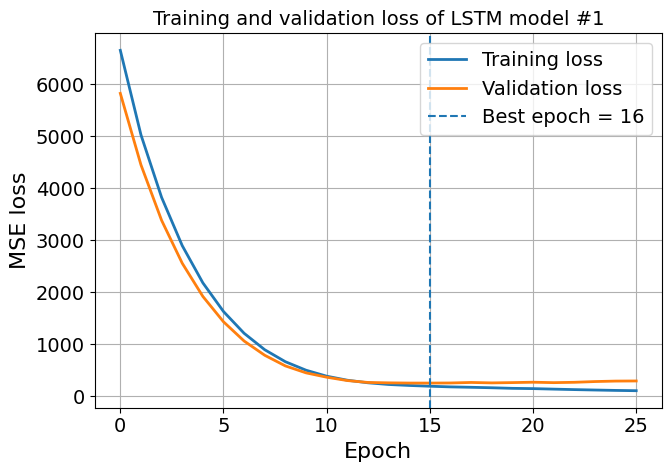

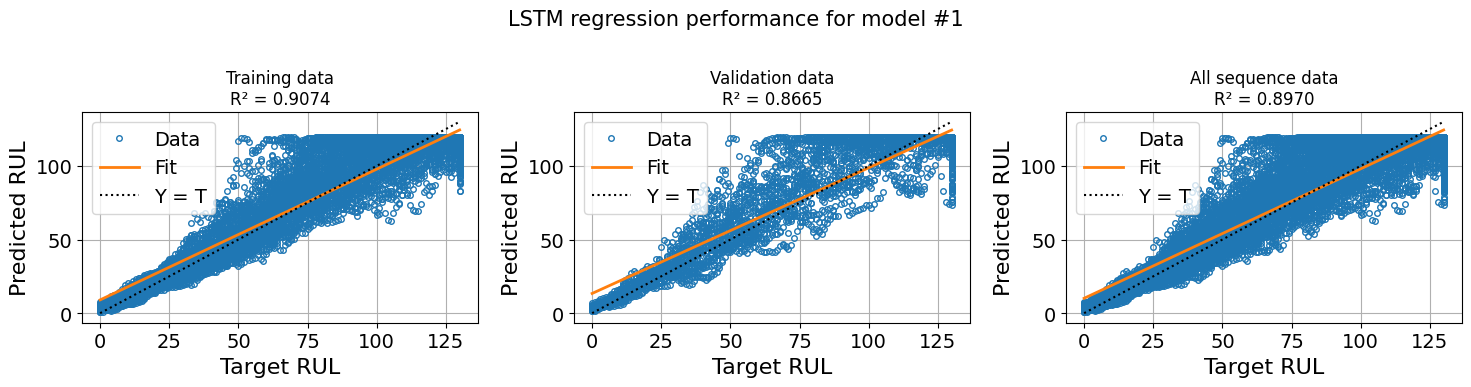

LSTM model #1
  Training RMSE   = 13.1917
  Validation RMSE = 15.8335
  All-data RMSE   = 13.9090

Average RMSE over repeated LSTM models
  Training RMSE   = 13.1917
  Validation RMSE = 15.8335
  All-data RMSE   = 13.9090


In [ ]:
# Plot training and validation loss

model_id = 0

history = lstm_histories[model_id]

train_loss = history.history["loss"]
valid_loss = history.history["val_loss"]

best_epoch = np.argmin(valid_loss) + 1

plt.figure(figsize=(7, 5))

plt.plot(train_loss, label="Training loss", linewidth=2)

plt.plot(valid_loss, label="Validation loss", linewidth=2)

plt.axvline(
    best_epoch - 1, linestyle="--", linewidth=1.5, label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch"); plt.ylabel("MSE loss")

plt.title(
    f"Training and validation loss of {model_type} model #{model_id + 1}", fontsize=14
)

plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()

from sklearn.metrics import r2_score

# R2 regression plot function

# R2 regression plots for LSTM

model_id = 0
model_lstm = lstm_models[model_id]

x_train_seq = lstm_split_data[model_id]["x_train"]
y_train_seq = lstm_split_data[model_id]["y_train"]

x_valid_seq = lstm_split_data[model_id]["x_valid"]
y_valid_seq = lstm_split_data[model_id]["y_valid"]

y_train_pred = (
    model_lstm(tf.convert_to_tensor(x_train_seq, dtype=tf.float32), training=False)
    .numpy()
    .ravel()
)

y_valid_pred = (
    model_lstm(tf.convert_to_tensor(x_valid_seq, dtype=tf.float32), training=False)
    .numpy()
    .ravel()
)

y_all_pred = (
    model_lstm(tf.convert_to_tensor(X_seq, dtype=tf.float32), training=False)
    .numpy()
    .ravel()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_regression_r2_subplot(axes[0], y_train_seq, y_train_pred, title="Training data")

plot_regression_r2_subplot(axes[1], y_valid_seq, y_valid_pred, title="Validation data")

plot_regression_r2_subplot(axes[2], y_seq, y_all_pred, title="All sequence data")

plt.suptitle(
    f"{model_type} regression performance for model #{model_id + 1}", fontsize=15
)

plt.tight_layout(); plt.show()

from sklearn.metrics import mean_squared_error

# RMSE calculation for LSTM

rmse_train_list = []
rmse_valid_list = []
rmse_all_list = []

for model_id in range(nrep_lstm):

    model = lstm_models[model_id]

    x_train = lstm_split_data[model_id]["x_train"]
    y_train = lstm_split_data[model_id]["y_train"]

    x_valid = lstm_split_data[model_id]["x_valid"]
    y_valid = lstm_split_data[model_id]["y_valid"]

    y_train_pred = (
        model(tf.convert_to_tensor(x_train, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    y_valid_pred = (
        model(tf.convert_to_tensor(x_valid, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    y_all_pred = (
        model(tf.convert_to_tensor(X_seq, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    rmse_valid = np.sqrt(mean_squared_error(y_valid, y_valid_pred))
    rmse_all = np.sqrt(mean_squared_error(y_seq, y_all_pred))

    rmse_train_list.append(rmse_train)
    rmse_valid_list.append(rmse_valid)
    rmse_all_list.append(rmse_all)

    print(f"{model_type} model #{model_id + 1}")
    print(f"  Training RMSE   = {format_number(rmse_train, '.4f')}")
    print(f"  Validation RMSE = {format_number(rmse_valid, '.4f')}")
    print(f"  All-data RMSE   = {format_number(rmse_all, '.4f')}")
    print()

print(f"Average RMSE over repeated {model_type} models")
print(f"  Training RMSE   = {format_number(np.mean(rmse_train_list), '.4f')}")
print(f"  Validation RMSE = {format_number(np.mean(rmse_valid_list), '.4f')}")
print(f"  All-data RMSE   = {format_number(np.mean(rmse_all_list), '.4f')}")

### Predict RUL for training

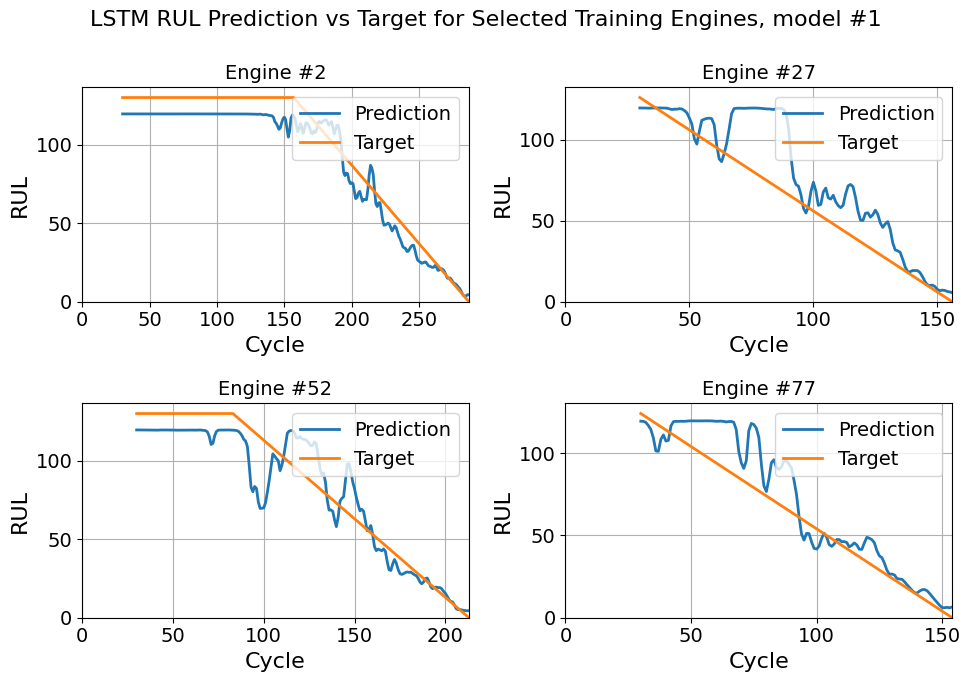

In [ ]:
# Plot RUL prediction vs target for selected training engines

display_engines = [2, 27, 52, 77]

model_id = 0
model_lstm = lstm_models[model_id]

plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):

    idx = eng_seq == eid

    cyc_e = cyc_seq[idx]
    X_e = X_seq[idx]
    y_true_e = y_seq[idx]

    X_e = np.asarray(X_e, dtype=np.float32)

    y_pred_e = (
        model_lstm(tf.convert_to_tensor(X_e, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    order = np.argsort(cyc_e)

    cyc_e = cyc_e[order]
    y_true_e = y_true_e[order]
    y_pred_e = y_pred_e[order]

    eol = int(cyc_e.max())

    plt.subplot(2, 2, ii)

    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)

    plt.plot(cyc_e, y_true_e, label="Target", linewidth=2)

    plt.title(f"Engine #{int(eid)}", fontsize=14)

    plt.xlabel("Cycle"); plt.ylabel("RUL")

    plt.xlim(0, eol); plt.ylim(bottom=0)

    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(
    f"{model_type} RUL Prediction vs Target for Selected Training Engines, model"
    f" #{model_id + 1}",
    fontsize=16,
)

plt.tight_layout(); plt.show()

### Load test set

In [ ]:
# Use the C-MAPSS subset selected in the training-data cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the matching test set

data_dir = DATA_ROOT / "CMAPSS"

test_file = data_dir / f"test_{dataName}.txt"
rul_file = data_dir / f"RUL_{dataName}.txt"

# Load test data and true final RUL

test_data = pd.read_csv(test_file, header=None, sep=r"\s+").values

true_rul_final = pd.read_csv(rul_file, header=None, sep=r"\s+").values.ravel()

# Test data construction

eng_num_test = test_data[:, 0]
cyc_test = test_data[:, 1]
op_test = test_data[:, 2:5]
sen_test = test_data[:, 5:26]

engine_ids_test = np.unique(eng_num_test)
n_test_engines = len(engine_ids_test)

### Process sensor test set

In [ ]:
# Normalize test selected sensors using training mean and std

selSen_test = sen_test[:, selOrd]
selSen_test_norm = (selSen_test - mu_train) / sigma_train_safe

# Gaussian smoothing of test selected sensors
# Engine by engine

# gauss_sigma = 1.0, kernel_size = 5 should be already defined previously.
selSen_test_smooth = np.zeros_like(selSen_test_norm)

for eid in engine_ids_test:

    idx_e = eng_num_test == eid

    for j in range(selSen_test_norm.shape[1]):

        selSen_test_smooth[idx_e, j] = gaussian_smooth_1d(
            selSen_test_norm[idx_e, j], gauss_sigma=gauss_sigma, kernel_size=kernel_size
        )

### Predict RUL for test

X_test_seq shape: (10196, 30, 10)
y_test_seq shape: (10196,)
FD001 test RMSE of LSTM = 16.4057
FD001 test Score of LSTM = 536.8873


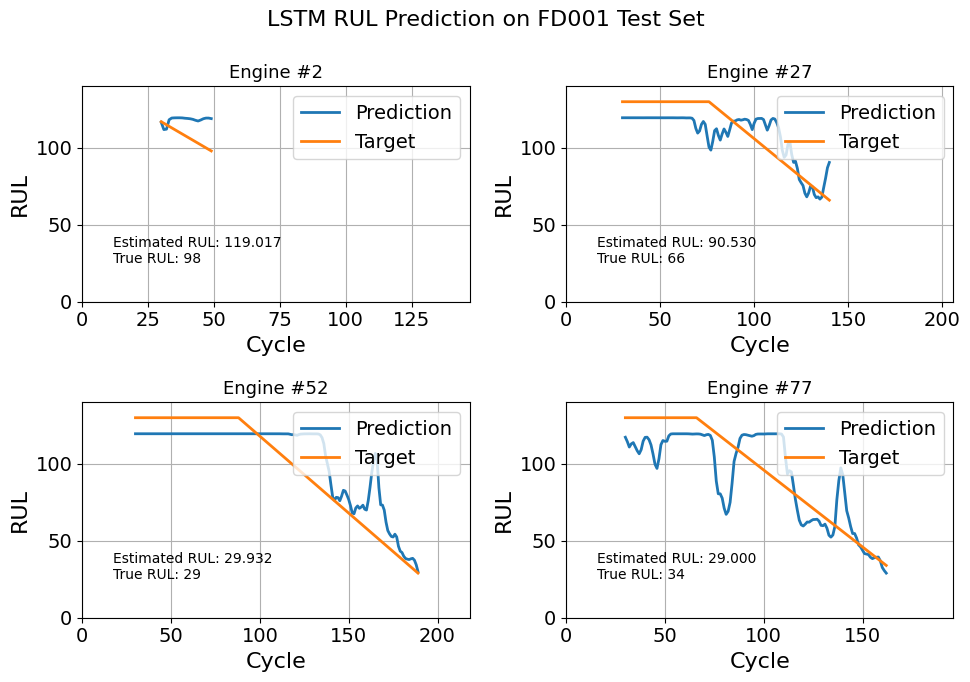

In [ ]:
display_engines = [2, 27, 52, 77]

# Reconstruct row-wise true RUL for test set

rul_test_row = np.zeros_like(cyc_test)

for i, eid in enumerate(engine_ids_test):

    idx_e = eng_num_test == eid
    cyc_e = cyc_test[idx_e]

    max_cycle_e = cyc_e.max()
    final_rul_e = true_rul_final[i]

    rul_test_row[idx_e] = final_rul_e + max_cycle_e - cyc_e

# Convert test data to LSTM sequence data

X_test_seq, y_test_seq, eng_test_seq, cyc_test_seq = make_sequence_data_no_padding(
    selSen_test_smooth,
    rul_test_row,
    eng_num_test,
    cyc_test,
    window_length=window_length,
)

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

# Predict RUL on test set

model_id = 0
model_lstm = lstm_models[model_id]

X_test_seq = np.asarray(X_test_seq, dtype=np.float32)

pred_test_seq = (
    model_lstm(tf.convert_to_tensor(X_test_seq, dtype=tf.float32), training=False)
    .numpy()
    .ravel()
)

# Final RUL prediction for each test engine
# Official evaluation uses the last observed cycle of each engine

pred_rul_final = np.zeros(len(engine_ids_test))

for i, eid in enumerate(engine_ids_test):

    idx_e = np.where(eng_test_seq == eid)[0]

    # Last observed cycle
    last_idx = idx_e[np.argmax(cyc_test_seq[idx_e])]

    pred_rul_final[i] = pred_test_seq[last_idx]

# RMSE and C-MAPSS score

errors = pred_rul_final - true_rul_final

rmse_test = np.sqrt(np.mean(errors**2))

score_each = np.zeros_like(errors)

for i, d in enumerate(errors):

    if d < 0:
        score_each[i] = np.exp(-d / 13.0) - 1.0
    else:
        score_each[i] = np.exp(d / 10.0) - 1.0

score_test = np.sum(score_each)

print(f"{dataName} test RMSE of {model_type} = {format_number(rmse_test, '.4f')}")
print(f"{dataName} test Score of {model_type} = {format_number(score_test, '.4f')}")

# Plot RUL prediction vs target for selected test engines

plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):

    idx = eng_test_seq == eid

    cyc_e = cyc_test_seq[idx]
    y_pred_e = pred_test_seq[idx]

    order = np.argsort(cyc_e)

    cyc_e = cyc_e[order]
    y_pred_e = y_pred_e[order]

    epos = np.where(np.unique(eng_num_test) == eid)[0][0]

    final_rul_e = true_rul_final[epos]
    max_cycle_e = cyc_e.max()

    eol_cycle_e = max_cycle_e + final_rul_e

    target_uncapped = final_rul_e + max_cycle_e - cyc_e
    target_capped = np.minimum(target_uncapped, cmin)

    est_final = y_pred_e[-1]
    true_final = final_rul_e

    plt.subplot(2, 2, ii)

    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)

    plt.plot(cyc_e, target_capped, label="Target", linewidth=2)

    plt.xlabel("Cycle"); plt.ylabel("RUL")

    plt.xlim(0, eol_cycle_e); plt.ylim(0, cmin + 10)

    plt.title(f"Engine #{int(eid)}", fontsize=13)

    plt.text(
        0.08,
        0.18,
        f"Estimated RUL: {format_number(est_final, '.3f')}\nTrue RUL:"
        f" {format_number(true_final, '.0f')}",
        transform=plt.gca().transAxes,
        fontsize=10,
    )

    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(f"{model_type} RUL Prediction on {dataName} Test Set", fontsize=16)

plt.tight_layout(); plt.show()

# Transformer in prognosis

### Functions

In [ ]:
# Transformer model construction

# Purpose: build the C-MAPSS Transformer RUL model.
# Input: window_length, n_features, d_model, num_heads, ff_dim, dense_units, dropout_rate,
# learning_rate.
# Output: returned model.
# Used in: Transformer in prognosis; Transformer RUL prediction using 10% of training engines.
def build_transformer_model(
    window_length,
    n_features,
    d_model=64,
    num_heads=4,
    ff_dim=128,
    dense_units=30,
    dropout_rate=0.2,
    learning_rate=0.001,
):

    input_layer = tf.keras.layers.Input(shape=(window_length, n_features))

    # Project sensor features to Transformer dimension
    x = tf.keras.layers.Dense(d_model)(input_layer)

    # Learnable positional embedding
    x = LearnablePositionalEmbedding(
        window_length=window_length, d_model=d_model, name="positional_embedding"
    )(x)

    # Multi-head self-attention
    attn_output = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=d_model // num_heads
    )(x, x)

    attn_output = tf.keras.layers.Dropout(dropout_rate)(attn_output)

    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + attn_output)

    # Feed-forward network
    ffn = tf.keras.layers.Dense(ff_dim, activation="relu")(x)

    ffn = tf.keras.layers.Dropout(dropout_rate)(ffn)

    ffn = tf.keras.layers.Dense(d_model)(ffn)

    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn)

    # Sequence-to-one regression
    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dropout(dropout_rate)(x)

    x = tf.keras.layers.Dense(dense_units, activation="tanh")(x)

    output = tf.keras.layers.Dense(1, activation="linear")(x)

    model = tf.keras.Model(inputs=input_layer, outputs=output)

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(optimizer=optimizer, loss="mse", metrics=["mse"])

    return model

class LearnablePositionalEmbedding(tf.keras.layers.Layer):

    # Purpose: initialize the model layers and configuration.
    # Input: window_length, d_model, **kwargs.
    # Output: updated state or displayed result; no return value.
    def __init__(self, window_length, d_model, **kwargs):
        super().__init__(**kwargs)
        self.window_length = window_length
        self.d_model = d_model

    # Purpose: create trainable layer weights for the input shape.
    # Input: input_shape.
    # Output: updated state or displayed result; no return value.
    def build(self, input_shape):
        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(self.window_length, self.d_model),
            initializer="random_normal",
            trainable=True,
        )

    # Purpose: compute the Keras layer output.
    # Input: inputs.
    # Output: returned inputs + self.position_embeddings.
    def call(self, inputs):
        return inputs + self.position_embeddings

### Transformer training

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
window_length = 30  # Cycles in each complete input window
batch_size = 32  # Samples per training batch
max_epochs = 200  # Maximum training epochs
patience = 10  # Epochs without validation improvement
nrep_transformer = 1
dropout_rate = 0.2
learning_rate = 0.001  # Optimizer learning rate

import time

# Set the epoch reporting interval

import tensorflow as tf
import numpy as np

# Reproducibility
tf.keras.utils.set_random_seed(0)
tf.config.experimental.enable_op_determinism()

# Transformer training settings

model_type = "Transformer"

# Time-window sequence setting

# Training settings

# Transformer hyperparameters
d_model = 64
num_heads = 4
ff_dim = 128
dense_units = 30

# Containers for repeated training
transformer_models = []
transformer_histories = []
transformer_split_data = []

# Row-wise input and target
X_row = selSen_smooth
y_row = rul

# Convert row-wise data to time-window sequence data
X_seq, y_seq, eng_seq, cyc_seq = make_sequence_data_no_padding(
    X_row, y_row, eng_num, cyc, window_length=window_length
)

print("X_seq shape:", X_seq.shape)
print("y_seq shape:", y_seq.shape)
print("eng_seq shape:", eng_seq.shape)
print("cyc_seq shape:", cyc_seq.shape)

# Train repeated Transformer models

from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping
from tqdm import tqdm
import time

start_time = time.perf_counter()

for rep in tqdm(range(nrep_transformer)):

    # --------------------------------------------------------
    # Engine-wise train/validation split
    # --------------------------------------------------------
    engine_ids = np.unique(eng_seq)

    train_engines, valid_engines = train_test_split(
        engine_ids, train_size=0.75, test_size=0.25, shuffle=True, random_state=rep
    )

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)

    x_train_seq = X_seq[idx_train]
    y_train_seq = y_seq[idx_train]

    x_valid_seq = X_seq[idx_valid]
    y_valid_seq = y_seq[idx_valid]

    # --------------------------------------------------------
    # Build Transformer model
    # --------------------------------------------------------
    model_transformer = build_transformer_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        d_model=d_model,
        num_heads=num_heads,
        ff_dim=ff_dim,
        dense_units=dense_units,
        dropout_rate=dropout_rate,
        learning_rate=learning_rate,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", mode="min", patience=patience, restore_best_weights=True
    )

    # --------------------------------------------------------
    # Train Transformer model
    # --------------------------------------------------------
    # Report the model and data before training
    show_model_info(model_transformer, x_train_seq, x_valid_seq)
    training_started = time.perf_counter()
    history = model_transformer.fit(
        x_train_seq,
        y_train_seq,
        batch_size=batch_size,
        epochs=max_epochs,
        validation_data=(x_valid_seq, y_valid_seq),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    transformer_models.append(model_transformer)
    transformer_histories.append(history)

    transformer_split_data.append(
        {
            "x_train": x_train_seq,
            "y_train": y_train_seq,
            "x_valid": x_valid_seq,
            "y_valid": y_valid_seq,
            "train_engines": train_engines,
            "valid_engines": valid_engines,
        }
    )

end_time = time.perf_counter()

print(
    "Transformer training time ="
    f" {format_number((end_time - start_time) / 60, '.2f')} min"
)

X_seq shape: (17731, 30, 10)
y_seq shape: (17731,)
eng_seq shape: (17731,)
cyc_seq shape: (17731,)


100%|██████████| 1/1 [08:03<00:00, 483.82s/it]

Transformer training time = 8.06 min


Model: "functional_22"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_22      │ (None, 30, 10)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (None, 30, 64)    │        704 │ input_layer_22[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 30, 64)    │      1,920 │ dense_44[0][0]    │
│ (LearnablePosition… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 64)    │     16,640 │ positional_embed… │
│ (MultiHeadAttentio… │                   │            │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_23          │ (None, 30, 64)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 64)    │          0 │ positional_embed… │
│                     │                   │            │ dropout_23[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (None, 30, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_24          │ (None, 30, 128)   │          0 │ dense_45[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_46 (Dense)    │ (None, 30, 64)    │      8,256 │ dropout_24[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_46[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_25          │ (None, 64)        │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_47 (Dense)    │ (None, 30)        │      1,950 │ dropout_25[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_48 (Dense)    │ (None, 1)         │         31 │ dense_47[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 114,233 (446.23 KB)

 Trainable params: 38,077 (148.74 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 76,156 (297.49 KB)

### Plot train val loss & R2

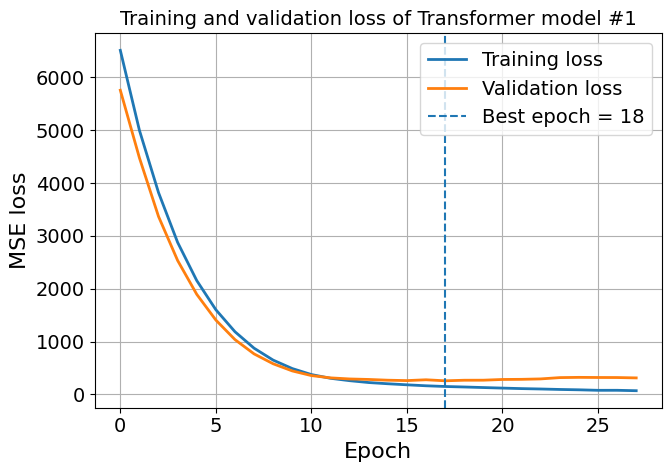

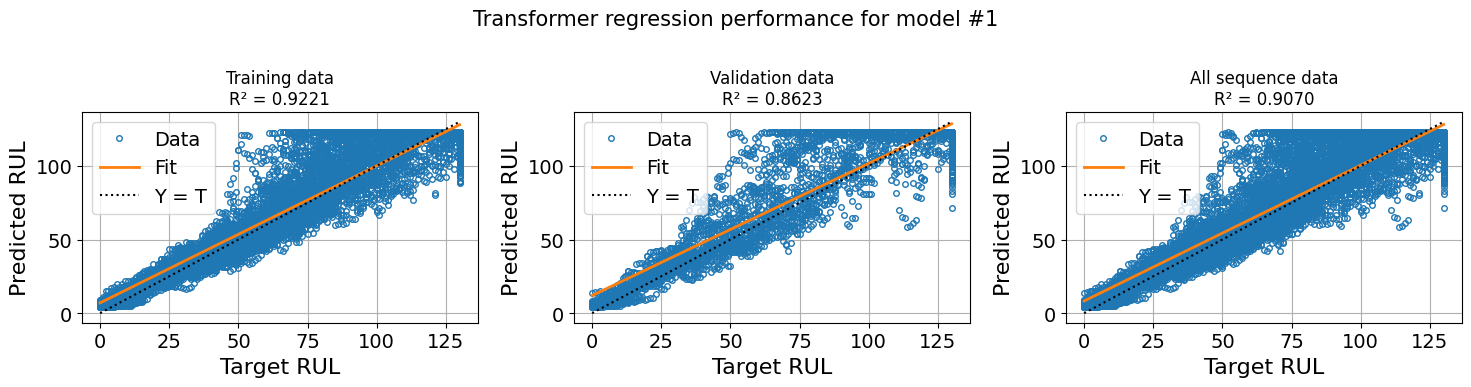

Transformer model #1
  Training RMSE   = 12.0970
  Validation RMSE = 16.0826
  All-data RMSE   = 13.2215

Average RMSE over repeated Transformer models
  Training RMSE   = 12.0970
  Validation RMSE = 16.0826
  All-data RMSE   = 13.2215


In [ ]:
# Plot training and validation loss

model_id = 0

history = transformer_histories[model_id]

train_loss = history.history["loss"]
valid_loss = history.history["val_loss"]

best_epoch = np.argmin(valid_loss) + 1

plt.figure(figsize=(7, 5))

plt.plot(train_loss, label="Training loss", linewidth=2)

plt.plot(valid_loss, label="Validation loss", linewidth=2)

plt.axvline(
    best_epoch - 1, linestyle="--", linewidth=1.5, label=f"Best epoch = {best_epoch}"
)

plt.xlabel("Epoch"); plt.ylabel("MSE loss")

plt.title(
    f"Training and validation loss of {model_type} model #{model_id + 1}", fontsize=14
)

plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()

from sklearn.metrics import r2_score

# R2 regression plot function

# R2 regression plots for Transformer

model_id = 0
model_transformer = transformer_models[model_id]

x_train_seq = transformer_split_data[model_id]["x_train"]
y_train_seq = transformer_split_data[model_id]["y_train"]

x_valid_seq = transformer_split_data[model_id]["x_valid"]
y_valid_seq = transformer_split_data[model_id]["y_valid"]

y_train_pred = (
    model_transformer(
        tf.convert_to_tensor(x_train_seq, dtype=tf.float32), training=False
    )
    .numpy()
    .ravel()
)

y_valid_pred = (
    model_transformer(
        tf.convert_to_tensor(x_valid_seq, dtype=tf.float32), training=False
    )
    .numpy()
    .ravel()
)

y_all_pred = (
    model_transformer(tf.convert_to_tensor(X_seq, dtype=tf.float32), training=False)
    .numpy()
    .ravel()
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_regression_r2_subplot(axes[0], y_train_seq, y_train_pred, title="Training data")

plot_regression_r2_subplot(axes[1], y_valid_seq, y_valid_pred, title="Validation data")

plot_regression_r2_subplot(axes[2], y_seq, y_all_pred, title="All sequence data")

plt.suptitle(
    f"{model_type} regression performance for model #{model_id + 1}", fontsize=15
)

plt.tight_layout(); plt.show()

from sklearn.metrics import mean_squared_error

# RMSE calculation for Transformer

rmse_train_list = []
rmse_valid_list = []
rmse_all_list = []

for model_id in range(nrep_transformer):

    model = transformer_models[model_id]

    x_train = transformer_split_data[model_id]["x_train"]
    y_train = transformer_split_data[model_id]["y_train"]

    x_valid = transformer_split_data[model_id]["x_valid"]
    y_valid = transformer_split_data[model_id]["y_valid"]

    y_train_pred = (
        model(tf.convert_to_tensor(x_train, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    y_valid_pred = (
        model(tf.convert_to_tensor(x_valid, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    y_all_pred = (
        model(tf.convert_to_tensor(X_seq, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    rmse_valid = np.sqrt(mean_squared_error(y_valid, y_valid_pred))
    rmse_all = np.sqrt(mean_squared_error(y_seq, y_all_pred))

    rmse_train_list.append(rmse_train)
    rmse_valid_list.append(rmse_valid)
    rmse_all_list.append(rmse_all)

    print(f"{model_type} model #{model_id + 1}")
    print(f"  Training RMSE   = {format_number(rmse_train, '.4f')}")
    print(f"  Validation RMSE = {format_number(rmse_valid, '.4f')}")
    print(f"  All-data RMSE   = {format_number(rmse_all, '.4f')}")
    print()

print(f"Average RMSE over repeated {model_type} models")
print(f"  Training RMSE   = {format_number(np.mean(rmse_train_list), '.4f')}")
print(f"  Validation RMSE = {format_number(np.mean(rmse_valid_list), '.4f')}")
print(f"  All-data RMSE   = {format_number(np.mean(rmse_all_list), '.4f')}")

### Predict RUL for training

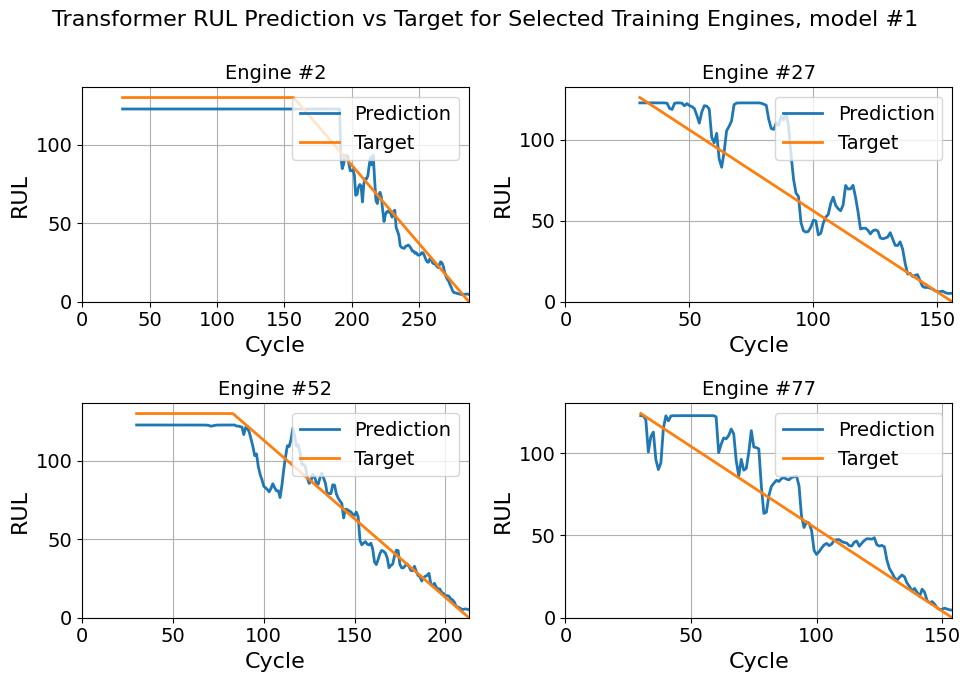

In [ ]:
# Plot RUL prediction vs target for selected training engines

display_engines = [2, 27, 52, 77]

model_id = 0
model_transformer = transformer_models[model_id]

plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):

    idx = eng_seq == eid

    cyc_e = cyc_seq[idx]
    X_e = X_seq[idx]
    y_true_e = y_seq[idx]

    X_e = np.asarray(X_e, dtype=np.float32)

    y_pred_e = (
        model_transformer(tf.convert_to_tensor(X_e, dtype=tf.float32), training=False)
        .numpy()
        .ravel()
    )

    order = np.argsort(cyc_e)

    cyc_e = cyc_e[order]
    y_true_e = y_true_e[order]
    y_pred_e = y_pred_e[order]

    eol = int(cyc_e.max())

    plt.subplot(2, 2, ii)

    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)

    plt.plot(cyc_e, y_true_e, label="Target", linewidth=2)

    plt.title(f"Engine #{int(eid)}", fontsize=14)

    plt.xlabel("Cycle"); plt.ylabel("RUL")

    plt.xlim(0, eol); plt.ylim(bottom=0)

    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(
    f"{model_type} RUL Prediction vs Target for Selected Training Engines, model"
    f" #{model_id + 1}",
    fontsize=16,
)

plt.tight_layout(); plt.show()

### Load test set

In [ ]:
# Use the C-MAPSS subset selected in the training-data cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the matching test set

data_dir = DATA_ROOT / "CMAPSS"

test_file = data_dir / f"test_{dataName}.txt"
rul_file = data_dir / f"RUL_{dataName}.txt"

# Load test data and true final RUL

test_data = pd.read_csv(test_file, header=None, sep=r"\s+").values

true_rul_final = pd.read_csv(rul_file, header=None, sep=r"\s+").values.ravel()

# Test data construction

eng_num_test = test_data[:, 0]
cyc_test = test_data[:, 1]
op_test = test_data[:, 2:5]
sen_test = test_data[:, 5:26]

engine_ids_test = np.unique(eng_num_test)
n_test_engines = len(engine_ids_test)

### Process sensor test set

In [ ]:
# Normalize test selected sensors using training mean and std

selSen_test = sen_test[:, selOrd]
selSen_test_norm = (selSen_test - mu_train) / sigma_train_safe

# Gaussian smoothing of test selected sensors
# Engine by engine

# gauss_sigma = 1.0, kernel_size = 5 should be already defined previously.
selSen_test_smooth = np.zeros_like(selSen_test_norm)

for eid in engine_ids_test:

    idx_e = eng_num_test == eid

    for j in range(selSen_test_norm.shape[1]):

        selSen_test_smooth[idx_e, j] = gaussian_smooth_1d(
            selSen_test_norm[idx_e, j], gauss_sigma=gauss_sigma, kernel_size=kernel_size
        )

### Predict RUL for test

X_test_seq shape: (10196, 30, 10)
y_test_seq shape: (10196,)
FD001 test RMSE of Transformer = 17.4490
FD001 test Score of Transformer = 624.1406


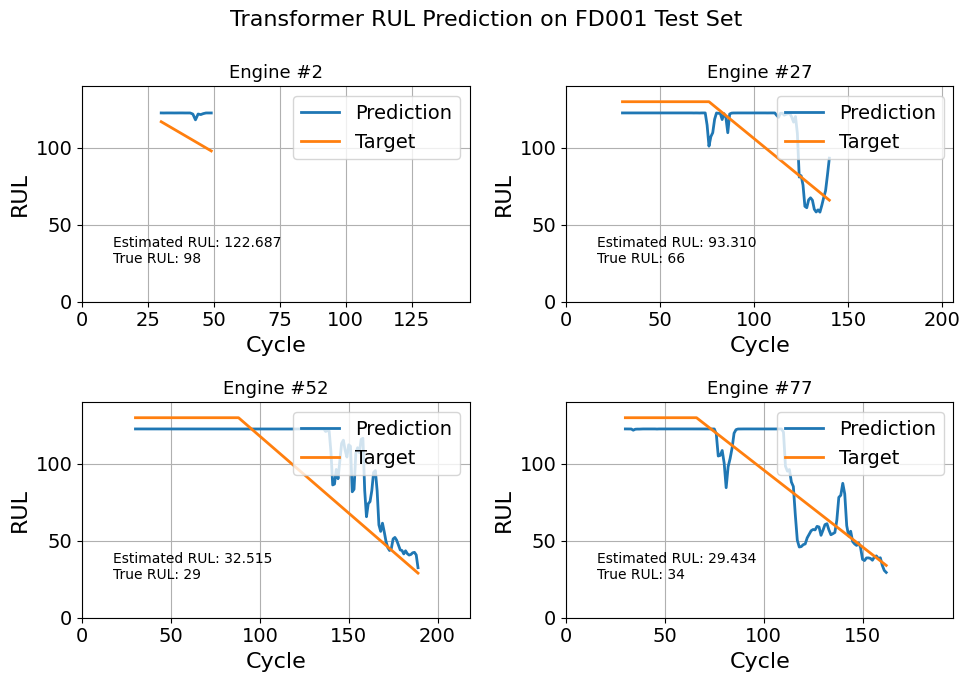

In [ ]:
display_engines = [2, 27, 52, 77]

# Reconstruct row-wise true RUL for test set

rul_test_row = np.zeros_like(cyc_test)

for i, eid in enumerate(engine_ids_test):

    idx_e = eng_num_test == eid
    cyc_e = cyc_test[idx_e]

    max_cycle_e = cyc_e.max()
    final_rul_e = true_rul_final[i]

    rul_test_row[idx_e] = final_rul_e + max_cycle_e - cyc_e

# Convert test data to Transformer sequence data

X_test_seq, y_test_seq, eng_test_seq, cyc_test_seq = make_sequence_data_no_padding(
    selSen_test_smooth,
    rul_test_row,
    eng_num_test,
    cyc_test,
    window_length=window_length,
)

print("X_test_seq shape:", X_test_seq.shape)
print("y_test_seq shape:", y_test_seq.shape)

# Predict RUL on test set

model_id = 0
model_transformer = transformer_models[model_id]

X_test_seq = np.asarray(X_test_seq, dtype=np.float32)

pred_test_seq = (
    model_transformer(
        tf.convert_to_tensor(X_test_seq, dtype=tf.float32), training=False
    )
    .numpy()
    .ravel()
)

# Final RUL prediction for each test engine
# Official evaluation uses the last observed cycle of each engine

pred_rul_final = np.zeros(len(engine_ids_test))

for i, eid in enumerate(engine_ids_test):

    idx_e = np.where(eng_test_seq == eid)[0]

    # Last observed cycle
    last_idx = idx_e[np.argmax(cyc_test_seq[idx_e])]

    pred_rul_final[i] = pred_test_seq[last_idx]

# RMSE and C-MAPSS score

errors = pred_rul_final - true_rul_final

rmse_test = np.sqrt(np.mean(errors**2))

score_each = np.zeros_like(errors)

for i, d in enumerate(errors):

    if d < 0:
        score_each[i] = np.exp(-d / 13.0) - 1.0
    else:
        score_each[i] = np.exp(d / 10.0) - 1.0

score_test = np.sum(score_each)

print(f"{dataName} test RMSE of {model_type} = {format_number(rmse_test, '.4f')}")
print(f"{dataName} test Score of {model_type} = {format_number(score_test, '.4f')}")

# Plot RUL prediction vs target for selected test engines

plt.figure(figsize=(10, 7))

for ii, eid in enumerate(display_engines, start=1):

    idx = eng_test_seq == eid

    cyc_e = cyc_test_seq[idx]
    y_pred_e = pred_test_seq[idx]

    order = np.argsort(cyc_e)

    cyc_e = cyc_e[order]
    y_pred_e = y_pred_e[order]

    epos = np.where(np.unique(eng_num_test) == eid)[0][0]

    final_rul_e = true_rul_final[epos]
    max_cycle_e = cyc_e.max()

    eol_cycle_e = max_cycle_e + final_rul_e

    target_uncapped = final_rul_e + max_cycle_e - cyc_e
    target_capped = np.minimum(target_uncapped, cmin)

    est_final = y_pred_e[-1]
    true_final = final_rul_e

    plt.subplot(2, 2, ii)

    plt.plot(cyc_e, y_pred_e, label="Prediction", linewidth=2)

    plt.plot(cyc_e, target_capped, label="Target", linewidth=2)

    plt.xlabel("Cycle"); plt.ylabel("RUL")

    plt.xlim(0, eol_cycle_e); plt.ylim(0, cmin + 10)

    plt.title(f"Engine #{int(eid)}", fontsize=13)

    plt.text(
        0.08,
        0.18,
        f"Estimated RUL: {format_number(est_final, '.3f')}\nTrue RUL:"
        f" {format_number(true_final, '.0f')}",
        transform=plt.gca().transAxes,
        fontsize=10,
    )

    plt.grid(True); plt.legend(loc="upper right")

plt.suptitle(f"{model_type} RUL Prediction on {dataName} Test Set", fontsize=16)

plt.tight_layout(); plt.show()

# LSTM RUL prediction using 10% of training engines

Ten engines are selected from 100 training engines. 5-fold CV is  applied to engines with train:valid 8:2. Each trained model is evaluated using 100 test engines.

### Trial with seed 0

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
patience = 10  # Epochs without validation improvement
batch_size = 32  # Samples per training batch
maximum_epochs = 200  # Maximum training epochs
selection_seed = 0

import time

# Set the epoch reporting interval

# Neural training settings

# LSTM using 10 selected engines with five-fold cross-validation

from sklearn.model_selection import KFold

rng = np.random.default_rng(selection_seed)
engine_ids_all = np.sort(np.unique(eng_seq))
selected_engines_10 = np.sort(rng.choice(engine_ids_all, 10, replace=False))

kfold = KFold(n_splits=5, shuffle=True, random_state=0)
results_lstm_10, splits_10 = [], []
start_time = time.perf_counter()

print(f"Selected engines: {selected_engines_10.tolist()}")

for fold, (train_pos, valid_pos) in enumerate(kfold.split(selected_engines_10), start=1):

    train_engines = selected_engines_10[train_pos]
    valid_engines = selected_engines_10[valid_pos]

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)
    x_train, y_train = X_seq[idx_train], y_seq[idx_train]
    x_valid, y_valid = X_seq[idx_valid], y_seq[idx_valid]

    tf.keras.utils.set_random_seed(fold)
    model_lstm_10 = build_lstm_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        lstm_units=64,
        dense_units=30,
        dropout_rate=0.2,
        learning_rate=0.001,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_lstm_10, x_train, x_valid)
    training_started = time.perf_counter()
    history = model_lstm_10.fit(
        x_train,
        y_train,
        batch_size=batch_size,
        epochs=maximum_epochs,
        validation_data=(x_valid, y_valid),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    pred_test = model_lstm_10.predict(X_test_seq, verbose=0).ravel()
    pred_final = np.array(
        [pred_test[np.where(eng_test_seq == eid)[0][-1]] for eid in engine_ids_test]
    )

    errors = pred_final - true_rul_final
    rmse = np.sqrt(np.mean(errors**2))
    score = np.sum(
        np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    )

    results_lstm_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )
    splits_10.append({"Fold": fold, "Train": train_engines, "Validation": valid_engines})

    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}"
    )
    print(f"Train engines: {train_engines.tolist()}")
    print(f"Validation engines: {valid_engines.tolist()}")

results_lstm_10 = pd.DataFrame(results_lstm_10)
display(results_lstm_10.round(4))

print(
    "Training time ="
    f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
)
print(
    f"Test RMSE = {format_number(results_lstm_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_lstm_10['Test RMSE'].std(), '.4f')}"
)
print(
    f"C-MAPSS Score = {format_number(results_lstm_10['C-MAPSS Score'].mean(), '.2f')} ±"
    f" {format_number(results_lstm_10['C-MAPSS Score'].std(), '.2f')}"
)

results_lstm_seed0 = results_lstm_10.copy()
selected_engines_seed0 = selected_engines_10.copy()

Selected engines: [2.0, 4.0, 8.0, 18.0, 26.0, 30.0, 48.0, 59.0, 78.0, 82.0]
Fold 1: RMSE = 21.0089, Score = 1019.40
Train engines: [2.0, 4.0, 18.0, 26.0, 30.0, 48.0, 59.0, 82.0]
Validation engines: [8.0, 78.0]
Fold 2: RMSE = 20.0139, Score = 944.92
Train engines: [2.0, 4.0, 8.0, 18.0, 30.0, 48.0, 59.0, 78.0]
Validation engines: [26.0, 82.0]
Fold 3: RMSE = 20.4787, Score = 932.17
Train engines: [2.0, 8.0, 18.0, 26.0, 30.0, 59.0, 78.0, 82.0]
Validation engines: [4.0, 48.0]
Fold 4: RMSE = 19.7969, Score = 596.05
Train engines: [2.0, 4.0, 8.0, 26.0, 30.0, 48.0, 78.0, 82.0]
Validation engines: [18.0, 59.0]
Fold 5: RMSE = 21.9666, Score = 1236.22
Train engines: [4.0, 8.0, 18.0, 26.0, 48.0, 59.0, 78.0, 82.0]
Validation engines: [2.0, 30.0]


,Fold,Best epoch,Test RMSE,C-MAPSS Score
0,1,131,21.0089,1019.3985
1,2,111,20.0139,944.9181
2,3,122,20.4787,932.1719
3,4,147,19.7969,596.0531
4,5,135,21.9666,1236.2179


Training time = 14.33 min
Test RMSE = 20.6530 ± 0.8695
C-MAPSS Score = 945.75 ± 230.36


### Another trial with seed 1

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
patience = 10  # Epochs without validation improvement
batch_size = 32  # Samples per training batch
maximum_epochs = 200  # Maximum training epochs
selection_seed = 1

import time

# Set the epoch reporting interval

# Neural training settings

# LSTM using 10 selected engines with five-fold cross-validation

from sklearn.model_selection import KFold

rng = np.random.default_rng(selection_seed)
engine_ids_all = np.sort(np.unique(eng_seq))
selected_engines_10 = np.sort(rng.choice(engine_ids_all, 10, replace=False))

kfold = KFold(n_splits=5, shuffle=True, random_state=0)
results_lstm_10, splits_10 = [], []
start_time = time.perf_counter()

print(f"Selected engines: {selected_engines_10.tolist()}")

for fold, (train_pos, valid_pos) in enumerate(kfold.split(selected_engines_10), start=1):

    train_engines = selected_engines_10[train_pos]
    valid_engines = selected_engines_10[valid_pos]

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)
    x_train, y_train = X_seq[idx_train], y_seq[idx_train]
    x_valid, y_valid = X_seq[idx_valid], y_seq[idx_valid]

    tf.keras.utils.set_random_seed(fold)
    model_lstm_10 = build_lstm_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        lstm_units=64,
        dense_units=30,
        dropout_rate=0.2,
        learning_rate=0.001,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_lstm_10, x_train, x_valid)
    training_started = time.perf_counter()
    history = model_lstm_10.fit(
        x_train,
        y_train,
        batch_size=batch_size,
        epochs=maximum_epochs,
        validation_data=(x_valid, y_valid),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    pred_test = model_lstm_10.predict(X_test_seq, verbose=0).ravel()
    pred_final = np.array(
        [pred_test[np.where(eng_test_seq == eid)[0][-1]] for eid in engine_ids_test]
    )

    errors = pred_final - true_rul_final
    rmse = np.sqrt(np.mean(errors**2))
    score = np.sum(
        np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    )

    results_lstm_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )
    splits_10.append({"Fold": fold, "Train": train_engines, "Validation": valid_engines})

    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}"
    )
    print(f"Train engines: {train_engines.tolist()}")
    print(f"Validation engines: {valid_engines.tolist()}")

results_lstm_10 = pd.DataFrame(results_lstm_10)
display(results_lstm_10.round(4))

print(
    "Training time ="
    f" {format_number((time.perf_counter() - start_time) / 60, '.2f')} min"
)
print(
    f"Test RMSE = {format_number(results_lstm_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_lstm_10['Test RMSE'].std(), '.4f')}"
)
print(
    f"C-MAPSS Score = {format_number(results_lstm_10['C-MAPSS Score'].mean(), '.2f')} ±"
    f" {format_number(results_lstm_10['C-MAPSS Score'].std(), '.2f')}"
)

results_lstm_seed1 = results_lstm_10.copy()
selected_engines_seed1 = selected_engines_10.copy()

Selected engines: [4.0, 14.0, 25.0, 32.0, 44.0, 48.0, 71.0, 80.0, 90.0, 93.0]
Fold 1: RMSE = 17.5700, Score = 450.69
Train engines: [4.0, 14.0, 32.0, 44.0, 48.0, 71.0, 80.0, 93.0]
Validation engines: [25.0, 90.0]
Fold 2: RMSE = 23.0613, Score = 1770.31
Train engines: [4.0, 14.0, 25.0, 32.0, 48.0, 71.0, 80.0, 90.0]
Validation engines: [44.0, 93.0]
Fold 3: RMSE = 19.4532, Score = 749.58
Train engines: [4.0, 25.0, 32.0, 44.0, 48.0, 80.0, 90.0, 93.0]
Validation engines: [14.0, 71.0]
Fold 4: RMSE = 19.9384, Score = 570.16
Train engines: [4.0, 14.0, 25.0, 44.0, 48.0, 71.0, 90.0, 93.0]
Validation engines: [32.0, 80.0]
Fold 5: RMSE = 18.6514, Score = 511.52
Train engines: [14.0, 25.0, 32.0, 44.0, 71.0, 80.0, 90.0, 93.0]
Validation engines: [4.0, 48.0]


,Fold,Best epoch,Test RMSE,C-MAPSS Score
0,1,138,17.5700,450.6919
1,2,102,23.0613,1770.3094
2,3,144,19.4532,749.5837
3,4,107,19.9384,570.1559
4,5,135,18.6514,511.5245


Training time = 12.66 min
Test RMSE = 19.7348 ± 2.0644
C-MAPSS Score = 810.45 ± 548.08


### Comparison

In [ ]:
comparison_selection_seed = pd.DataFrame(
    {
        "Selection seed": [0, 1],
        "Selected engines": [
            selected_engines_seed0.tolist(),
            selected_engines_seed1.tolist(),
        ],
        "Test RMSE mean": [
            results_lstm_seed0["Test RMSE"].mean(),
            results_lstm_seed1["Test RMSE"].mean(),
        ],
        "Test RMSE std": [
            results_lstm_seed0["Test RMSE"].std(),
            results_lstm_seed1["Test RMSE"].std(),
        ],
        "C-MAPSS Score mean": [
            results_lstm_seed0["C-MAPSS Score"].mean(),
            results_lstm_seed1["C-MAPSS Score"].mean(),
        ],
        "C-MAPSS Score std": [
            results_lstm_seed0["C-MAPSS Score"].std(),
            results_lstm_seed1["C-MAPSS Score"].std(),
        ],
    }
)

display(comparison_selection_seed.round(2))

,Selection seed,Selected engines,Test RMSE mean,Test RMSE std,C-MAPSS Score mean,C-MAPSS Score std
0,0,"[2.0, 4.0, 8.0, 18.0, 26.0, 30.0, 48.0, 59.0, ...",20.65,0.87,945.75,230.36
1,1,"[4.0, 14.0, 25.0, 32.0, 44.0, 48.0, 71.0, 80.0...",19.73,2.06,810.45,548.08


# 1D CNN RUL prediction using 10% of training engines

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
patience = 10  # Epochs without validation improvement
batch_size = 32  # Samples per training batch
maximum_epochs = 1000  # Maximum training epochs
selection_seed = 0

import time

# Set the epoch reporting interval

# Neural training settings

from sklearn.model_selection import KFold

engine_ids_all = np.sort(np.unique(eng_seq))
rng = np.random.default_rng(selection_seed)
selected_engines_10 = np.sort(rng.choice(engine_ids_all, 10, replace=False))
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

results_cnn_10, splits_cnn_10 = [], []
start_time = time.perf_counter()
print(f"Selected engines: {selected_engines_10.tolist()}")

for fold, (train_pos, valid_pos) in enumerate(kfold.split(selected_engines_10), start=1):

    fold_start = time.perf_counter()
    train_engines = selected_engines_10[train_pos]
    valid_engines = selected_engines_10[valid_pos]

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)
    x_train, y_train = X_seq[idx_train], y_seq[idx_train]
    x_valid, y_valid = X_seq[idx_valid], y_seq[idx_valid]

    tf.keras.utils.set_random_seed(fold)
    model_cnn_10 = build_cnn_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        cnn_type="1d",
        dropout_rate=0.2,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_cnn_10, x_train, x_valid)
    training_started = time.perf_counter()
    history = model_cnn_10.fit(
        x_train,
        y_train,
        batch_size=batch_size,
        epochs=maximum_epochs,
        validation_data=(x_valid, y_valid),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    pred_test = model_cnn_10.predict(X_test_seq, verbose=0).ravel()
    pred_final = np.array(
        [pred_test[np.where(eng_test_seq == eid)[0][-1]] for eid in engine_ids_test]
    )

    errors = pred_final - true_rul_final
    rmse = np.sqrt(np.mean(errors**2))
    score = np.sum(
        np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    )

    results_cnn_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )
    splits_cnn_10.append(
        {"Fold": fold, "Train": train_engines, "Validation": valid_engines}
    )

    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}, Time ="
        f" {format_number((time.perf_counter() - fold_start) / 60, '.2f')} min"
    )

results_cnn_10 = pd.DataFrame(results_cnn_10)
display(results_cnn_10.round(4))

print(f"Total time = {format_number((time.perf_counter() - start_time) / 60, '.2f')} min")
print(
    f"Test RMSE = {format_number(results_cnn_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_cnn_10['Test RMSE'].std(), '.4f')}"
)
print(
    f"C-MAPSS Score = {format_number(results_cnn_10['C-MAPSS Score'].mean(), '.2f')} ±"
    f" {format_number(results_cnn_10['C-MAPSS Score'].std(), '.2f')}"
)

Selected engines: [2.0, 4.0, 8.0, 18.0, 26.0, 30.0, 48.0, 59.0, 78.0, 82.0]
Fold 1: RMSE = 28.6377, Score = 2546.28, Time = 1.44 min
Fold 2: RMSE = 27.0991, Score = 1655.34, Time = 1.06 min
Fold 3: RMSE = 25.5263, Score = 1503.02, Time = 1.15 min
Fold 4: RMSE = 27.5903, Score = 1965.35, Time = 1.49 min
Fold 5: RMSE = 26.7930, Score = 19418.56, Time = 1.42 min


,Fold,Best epoch,Test RMSE,C-MAPSS Score
0,1,122,28.6377,2546.2790
1,2,84,27.0991,1655.3391
2,3,92,25.5263,1503.0235
3,4,124,27.5903,1965.3457
4,5,129,26.7930,19418.5568


Total time = 6.56 min
Test RMSE = 27.1293 ± 1.1370
C-MAPSS Score = 5417.71 ± 7836.90


# Transformer RUL prediction using 10% of training engines

In [ ]:
# User settings: change these values to repeat the experiment
progress_interval = 100  # Epoch interval for loss reporting
patience = 10  # Epochs without validation improvement
batch_size = 32  # Samples per training batch
maximum_epochs = 200  # Maximum training epochs
selection_seed = 0

import time

# Set the epoch reporting interval

# Neural training settings

from sklearn.model_selection import KFold

engine_ids_all = np.sort(np.unique(eng_seq))
rng = np.random.default_rng(selection_seed)
selected_engines_10 = np.sort(rng.choice(engine_ids_all, 10, replace=False))
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

results_transformer_10, splits_transformer_10 = [], []
start_time = time.perf_counter()
print(f"Selected engines: {selected_engines_10.tolist()}")

for fold, (train_pos, valid_pos) in enumerate(kfold.split(selected_engines_10), start=1):

    fold_start = time.perf_counter()
    train_engines = selected_engines_10[train_pos]
    valid_engines = selected_engines_10[valid_pos]

    idx_train = np.isin(eng_seq, train_engines)
    idx_valid = np.isin(eng_seq, valid_engines)
    x_train, y_train = X_seq[idx_train], y_seq[idx_train]
    x_valid, y_valid = X_seq[idx_valid], y_seq[idx_valid]

    tf.keras.utils.set_random_seed(fold)
    model_transformer_10 = build_transformer_model(
        window_length=window_length,
        n_features=X_seq.shape[2],
        d_model=64,
        num_heads=4,
        ff_dim=128,
        dense_units=30,
        dropout_rate=0.2,
        learning_rate=0.001,
    )

    early_stopping = EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )

    # Report the model and data before training
    show_model_info(model_transformer_10, x_train, x_valid)
    training_started = time.perf_counter()
    history = model_transformer_10.fit(
        x_train,
        y_train,
        batch_size=batch_size,
        epochs=maximum_epochs,
        validation_data=(x_valid, y_valid),
        callbacks=[early_stopping] + [training_progress(progress_interval)],
        verbose=0,
    )
    report_training(history, training_started)

    pred_test = model_transformer_10.predict(X_test_seq, verbose=0).ravel()

    pred_final = np.array(
        [pred_test[np.where(eng_test_seq == eid)[0][-1]] for eid in engine_ids_test]
    )

    errors = pred_final - true_rul_final
    rmse = np.sqrt(np.mean(errors**2))
    score = np.sum(
        np.where(errors < 0, np.exp(-errors / 13) - 1, np.exp(errors / 10) - 1)
    )

    results_transformer_10.append(
        {
            "Fold": fold,
            "Best epoch": np.argmin(history.history["val_loss"]) + 1,
            "Test RMSE": rmse,
            "C-MAPSS Score": score,
        }
    )
    splits_transformer_10.append(
        {"Fold": fold, "Train": train_engines, "Validation": valid_engines}
    )

    print(
        f"Fold {fold}: RMSE = {format_number(rmse, '.4f')}, Score ="
        f" {format_number(score, '.2f')}, Time ="
        f" {format_number((time.perf_counter() - fold_start) / 60, '.2f')} min"
    )

results_transformer_10 = pd.DataFrame(results_transformer_10)
display(results_transformer_10.round(4))

print(f"Total time = {format_number((time.perf_counter() - start_time) / 60, '.2f')} min")
print(
    f"Test RMSE = {format_number(results_transformer_10['Test RMSE'].mean(), '.4f')} ±"
    f" {format_number(results_transformer_10['Test RMSE'].std(), '.4f')}"
)
print(
    "C-MAPSS Score ="
    f" {format_number(results_transformer_10['C-MAPSS Score'].mean(), '.2f')} ±"
    f" {format_number(results_transformer_10['C-MAPSS Score'].std(), '.2f')}"
)

Selected engines: [2.0, 4.0, 8.0, 18.0, 26.0, 30.0, 48.0, 59.0, 78.0, 82.0]
Fold 1: RMSE = 20.1194, Score = 746.85, Time = 4.79 min
Fold 2: RMSE = 24.6212, Score = 1081.29, Time = 3.69 min
Fold 3: RMSE = 21.3491, Score = 851.43, Time = 4.88 min
Fold 4: RMSE = 21.8862, Score = 1236.53, Time = 5.12 min
Fold 5: RMSE = 23.7977, Score = 2649.46, Time = 4.62 min


,Fold,Best epoch,Test RMSE,C-MAPSS Score
0,1,114,20.1194,746.8503
1,2,94,24.6212,1081.2877
2,3,121,21.3491,851.4325
3,4,131,21.8862,1236.5286
4,5,133,23.7977,2649.4593


Total time = 23.10 min
Test RMSE = 22.3547 ± 1.8335
C-MAPSS Score = 1313.11 ± 771.24
